<a href="https://colab.research.google.com/github/dmecoyfin/dmeyf2026/blob/ensembles_2026/ensembles/z494_TareaHogar_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea para el Hogar 04

# ⚠️ CAMBIOS: Excluyendo registros dudosos de training
Todos los cambios están marcados con `>>> CAMBIO` ... `<<< FIN CAMBIO` y las celdas nuevas tienen un título **⚠️ CAMBIO**.

1. `campos_buenos` excluye `training30`, `prob30`, `aporta`, `fold30`
2. Celda nueva: `modelo30` entrenado con el fold 2
3. Celda nueva: `prob30` sobre el training de la BO
4. Celda nueva: `aporta` + `training` (ahora con `fold == 1`)
5. `dtrain` (sin cambio de lógica, solo controles)
6. Arreglo de sintaxis en el hardcodeo de hiperparámetros
7. Celda nueva: limpieza del training final por cross-fitting (**la que cambia el modelo sin BO**)

#  1. Big Picture

LightGBM es el algoritmo estado del arte para datasets estructurados.
<br> La Bayesian Optimization es el estado del arte para optimización de hiperparámetros
<br> Las soluciones a las tres competencias de la asignatura contendrán LightGBMs y Bayesian Optimizations
<br> LightGBM ha aumentado en forma no darwiniana sus hiperparámetros en los últimos ocho años; no todos los existentes son útiles.
<br> Es necesario lograr entender cuales son los hiperparámetros relevantes de LightGBM

# 2. Hiperparámetros del LightGBM

Los objetivos de esta tarea son:


*   Aumentar la rentabilidad de la campaña de marketing de retención proactiva de clientes.
*   Generar un mejor modelo optimizando sus hiperparámetros
*   Conceptual : investigar los mas relevantes hiperparámetros de LightGBM
*   Familiarizarse con la Bayesian Optimization, sus largos tiempos de corrida y opciones para reducirlos
*   Familiarizarse con el uso de máquinas virtuales de Google Colab
*   Ver un pipeline completo de optimización de hiperparámetros y puesta en producción

LightGBM cuenta con mas de 60 hiperparámetros, siendo posible utilizar 40 al mismo tiempo, aunque no razonable.
<br> La documentación oficial de los hiperparámetros de LightGBM es  https://lightgbm.readthedocs.io/en/latest/Parameters.html#core-parameters


Se lo alerta sobre que una Optimizacion Bayesiana lleva varias horas de corrida, y usted deberá correr VARIAS optimizaciones para descubrir cuales parámetros conviene optimizar.
<br> A pesar que la próxima clase es recien en viernes 01 de agosto, inicie la tarea con tiempo, aprenda a planificar estratégicamente sus corridas como un@ científ@  de datos.

Es necesario investigar cuales son los hiperparámetros de LightGBM que vale la pena optimizar en una Bayesian Optimization, ya que los realmente utiles son apenas un reducido subconjunto.
<br>Usted deberá investigar cuales son los hiperparámetros mas relevantes de LightGBM, su primer alternativa es preguntándole a su amigo con capacidades especiales ChatGPT o sus endogámicos familiares Claude, DeepSeek, Gemini, Grok, etc
<br> La segunda alternativa es la propia documentación de LightGBM  https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html


Adicionalmente podra buscar información como la que proveen esta diminuta muestra aleatoria de artículos ligeros:
*  https://medium.com/@sarahzouinina/a-deep-dive-into-lightgbm-how-to-choose-and-tune-parameters-7c584945842e
*  https://www.kaggle.com/code/somang1418/tuning-hyperparameters-under-10-minutes-lgbm
*  https://towardsdatascience.com/beginners-guide-to-the-must-know-lightgbm-hyperparameters-a0005a812702/


<br>  La muestra anterior se brinda a modo de ejemplo, usted deberá buscar muuuuchas  fuentes adicionales de información
<br> Tenga presente que LightGBM es el estado del arte en modelado predictivo para datasets estructurado, que son el 90% del trabajo del 95% de los Data Scientists en Argentina.

El desafío de esta tarea es:
* Qué hiperparparámetros conviene optimizar?  Las recomendaciones de los artículos ligeros es siempre sensata?  Sus autores realmente hicieron experimentos o son siemplemente escritores de entretenimiento carente de base científica?
* Elegidos los hiperparámetros, cual es el  <desde, hasta> que se debe utilizar en la Bayesian Optimization ?
* Realmente vale la pena optimizar 10 o 16 hiperparámetros al mismo tiempo ?  No resulta contraproducente una búsqueda en un espacio de tal alta dimensionalidad ?

## 2.1  Seteo del ambiente en Google Colab

Esta parte se debe correr con el runtime en Python3
<br>Ir al menu, Runtime -> Change Runtime Type -> Runtime type ->  **Python 3**

Conectar la virtual machine donde esta corriendo Google Colab con el  Google Drive, para poder tener persistencia de archivos

In [1]:
# primero establecer el Runtime de Python 3
# from google.colab import drive
# drive.mount('/content/.drive')

Para correr la siguiente celda es fundamental en Arranque en Frio haber copiado el archivo kaggle.json al Google Drive, en la carpeta indicada en el instructivo

<br>los siguientes comando estan en shell script de Linux
*   Crear las carpetas en el Google Drive
*   "instalar" el archivo kaggle.json desde el Google Drive a la virtual machine para que pueda ser utilizado por la libreria  kaggle de Python
*   Bajar el  **dataset_pequeno**  al  Google Drive  y tambien al disco local de la virtual machine que esta corriendo Google Colab



In [2]:
#%load_ext rpy2.ipython

In [3]:
require( "data.table" )

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%




In [4]:
#%%R
#DIR <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1"
DIR     <- path.expand("~/buckets/b1/datasets")

In [5]:
#dataset <- fread(file.path(DIR, "competencia_01_crudo.csv"))
dataset <- fread(file.path(DIR, "competencia_01_crudo.csv"))

In [6]:
#%%shell

#mkdir -p "/content/.drive/My Drive/dmeyf"
#mkdir -p "/content/buckets"
#ln -s "/content/.drive/My Drive/dmeyf" /content/buckets/b1


#mkdir -p /content/buckets/b1/exp
#mkdir -p /content/buckets/b1/datasets
#mkdir -p /content/datasets



#archivo_origen="https://storage.googleapis.com/open-courses/dmeyf2026-9c6f/competencia_01_crudo.csv"
#archivo_destino="/content/datasets/competencia_01_crudo.csv"
#archivo_destino_bucket="/content/buckets/b1/datasets/competencia_01_crudo.csv"

#if ! test -f $archivo_destino_bucket; then
#  wget  $archivo_origen  -O $archivo_destino_bucket
#fi


#if ! test -f $archivo_destino; then
#  cp  $archivo_destino_bucket  $archivo_destino
#fi


## Generacion de la clase_ternaria

Esta parte se debe correr con el runtime en lenguaje **R** Ir al menu, Runtime -> Change Runtime Tipe -> Runtime type -> R

In [7]:
#%%R

# calculo el periodo0 consecutivo
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 +  foto_mes%%100 ) ]


# ordeno
setorder( dsimple, numero_de_cliente, periodo0 )

# calculo topes
periodo_ultimo <- dsimple[, max(periodo0) ]
periodo_anteultimo <- periodo_ultimo - 1


# calculo los leads de orden 1 y 2
dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"),  numero_de_cliente ]

# assign most common class values = "CONTINUA"
dsimple[ periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA" ]

# calculo BAJA+1
dsimple[ periodo0 < periodo_ultimo &
    ( is.na(periodo1) | periodo0 + 1 < periodo1 ),
    clase_ternaria := "BAJA+1" ]

# calculo BAJA+2
dsimple[ periodo0 < periodo_anteultimo & (periodo0+1 == periodo1 )
    & ( is.na(periodo2) | periodo0 + 2 < periodo2 ),
    clase_ternaria := "BAJA+2" ]


# pego el resultado en el dataset original y grabo
setorder( dsimple, pos )
dataset[, clase_ternaria := dsimple$clase_ternaria ]

In [8]:
#%%R
#fwrite(dataset,
#    file = file.path(DIR, "competencia_01.csv.gz"),
#    sep = ","
#)

In [9]:
#%%R
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


In [10]:
ncol(dataset)

[1] 155

## vars_full_zero muestra qué columnas estuvieron completamente en cero en qué meses.

In [11]:
# Busco los features que tienen full_zero menos foto_mes y numero_de_cliente (preventivo)
numeric_cols <- names(dataset)[sapply(dataset, is.numeric)]
numeric_cols <- setdiff(numeric_cols, c("foto_mes", "numero_de_cliente"))

result_list <- list()

for(month in unique(dataset$foto_mes)) {
  month_data <- dataset[foto_mes == month, ..numeric_cols]
  
  # TODO CERO
  zero_cols <- numeric_cols[sapply(month_data, function(x) all(x == 0, na.rm = TRUE))]
  
  if(length(zero_cols) > 0) {
    result_list[[as.character(month)]] <- data.table(
      foto_mes = month,
      column_name = zero_cols
    )
  }
}

vars_full_zero <- rbindlist(result_list)
print(vars_full_zero)

# Aplico NULL 
#for(month in unique(vars_full_zero$foto_mes)){
#  vars_this_month <- vars_full_zero[foto_mes == month, column_name]
  
#  dataset[foto_mes == month,
#          (vars_this_month) := lapply(.SD, function(x) ifelse(x == 0, NA, x)),
#          .SDcols = vars_this_month]
#}

   foto_mes      column_name
      <int>           <char>
1:   202105 ccajas_depositos


### Les aplico NA

In [12]:
# Aplico NULL 
for(month in unique(vars_full_zero$foto_mes)){
  vars_this_month <- vars_full_zero[foto_mes == month, column_name]
  
  dataset[foto_mes == month,
          (vars_this_month) := lapply(.SD, function(x) ifelse(x == 0, NA, x)),
          .SDcols = vars_this_month]}

## NUEVO: variables _zero (flag 1/0/NA, no se rankean ni laguean)

In [13]:
# =====================================================================
# CAMBIO 2: variables _zero (FLAG de "la variable vale cero")
#   1  si la variable original vale 0
#   NA si la variable original es NA
#   0  en el resto de los casos
# Solo para las variables que ALGUNA VEZ valen cero (en cualquier mes).
# Se calculan sobre los valores CRUDOS (antes del rank, que pisa los montos).
# Estas columnas NO se rankean ni se laguean (ver celda de rank/lags).
# =====================================================================
cols_base_zero <- setdiff(colnames(dataset),
                          c("numero_de_cliente", "foto_mes", "clase_ternaria"))
cols_base_zero <- cols_base_zero[sapply(cols_base_zero, function(v) is.numeric(dataset[[v]]))]

tiene_cero <- dataset[, sapply(.SD, function(x) any(x == 0, na.rm = TRUE)),
                      .SDcols = cols_base_zero]
cols_zero  <- cols_base_zero[tiene_cero]

# as.integer(x == 0) da exactamente 1 / 0 / NA  (NA == 0 es NA)
dataset[, paste0(cols_zero, "_zero") := lapply(.SD, function(x) as.integer(x == 0)),
        .SDcols = cols_zero]

cat("Variables _zero creadas:", length(cols_zero), " ncol(dataset) =", ncol(dataset), "\n")

# control sobre un ejemplo
dataset[, list(uno  = sum(cpayroll_trx_zero == 1L, na.rm = TRUE),
               cero = sum(cpayroll_trx_zero == 0L, na.rm = TRUE),
               na   = sum(is.na(cpayroll_trx_zero))), by = foto_mes][order(foto_mes)]

Variables _zero creadas: 140  ncol(dataset) = 295 


foto_mes,uno,cero,na
<int>,<int>,<int>,<int>
202103,74880,88020,0
202104,74945,88339,0
202105,73761,90007,0
202106,73414,90700,0
202107,73680,90668,0
202108,72860,91787,0


## NUEVO: totales de tarjeta + ratios de utilizacion (ANTES del rank)

In [14]:
# =====================================================================
# NUEVO (va ANTES del rank): totales de tarjeta + RATIOS de utilizacion.
# Se calculan sobre monto CRUDO a proposito: un ratio de rankings no
# significa nada. Al empezar con "m", el grep ^m de la celda siguiente
# los rankea por mes (bien) y el loop de lags les da lag/delta
# (util: tendencia de la utilizacion mes a mes).
# =====================================================================
req_lim <- c("Master_mlimitecompra","Visa_mlimitecompra")
if (all(req_lim %in% colnames(dataset))) {
  dataset[, mv_mlimitecompra := rowSums(cbind(Master_mlimitecompra, Visa_mlimitecompra), na.rm = TRUE) ]

  if (all(c("Master_msaldototal","Visa_msaldototal") %in% colnames(dataset)))
    dataset[, mv_msaldototal   := rowSums(cbind(Master_msaldototal,   Visa_msaldototal),   na.rm = TRUE) ]
  if (all(c("Master_mconsumototal","Visa_mconsumototal") %in% colnames(dataset)))
    dataset[, mv_mconsumototal := rowSums(cbind(Master_mconsumototal, Visa_mconsumototal), na.rm = TRUE) ]
  if (all(c("Master_mpagado","Visa_mpagado") %in% colnames(dataset)))
    dataset[, mv_mpagado       := rowSums(cbind(Master_mpagado,       Visa_mpagado),       na.rm = TRUE) ]
  if (all(c("Master_mpagominimo","Visa_mpagominimo") %in% colnames(dataset)))
    dataset[, mv_mpagominimo   := rowSums(cbind(Master_mpagominimo,   Visa_mpagominimo),   na.rm = TRUE) ]

  # ratios de utilizacion (denominador = limite de compra total)
  if ("mv_msaldototal"   %in% colnames(dataset)) dataset[, mvr_utilizacion    := mv_msaldototal   / mv_mlimitecompra ]  # saldo/limite (el mas predictivo)
  if ("mv_mconsumototal" %in% colnames(dataset)) dataset[, mvr_consumo_limite := mv_mconsumototal / mv_mlimitecompra ]
  if ("mv_mpagado"       %in% colnames(dataset)) dataset[, mvr_pago_limite    := mv_mpagado       / mv_mlimitecompra ]
  if ("mv_mpagominimo"   %in% colnames(dataset)) dataset[, mvr_pagominimo_lim := mv_mpagominimo   / mv_mlimitecompra ]

  # division por limite 0 -> Inf/NaN -> NA
  for (cc in intersect(c("mvr_utilizacion","mvr_consumo_limite","mvr_pago_limite","mvr_pagominimo_lim"), colnames(dataset))) {
    malos <- which( is.infinite(dataset[[cc]]) | is.nan(dataset[[cc]]) )
    if (length(malos)) set(dataset, malos, cc, NA_real_)
  }
  cat("Ratios de utilizacion agregados (antes del rank). ncol =", ncol(dataset), "\n")
}


Ratios de utilizacion agregados (antes del rank). ncol = 304 


## Generación de lag1, delta1, lag2, delta2
Para cada campo del dataset original (*) se crean los siguientes campos de a partir de la historia:
- lag1 lags de orden 1
- delta1 valor actual - lag1
- lag2 lags de orden 2
- delta2 valor actual - lag2

Se pasa de 155 campos a 763

(*) Excepto para los campos [numero_de_cliente, foto_mes, clase_ternaria]

**Primero calculo ranking y despues lags y deltas sobre ranking**

In [15]:
# ---- NUEVO: ranking de variables monetarias por foto_mes (antes de lags y deltas) ----
# rank con cero fijo: 0 queda en 1e-7, positivos en (0,1], negativos en [-1,0), NA queda NA
rank_cero_fijo <- function(x) {
  y   <- rep(NA_real_, length(x))
  pos <- !is.na(x) & x > 0
  neg <- !is.na(x) & x < 0
  y[!is.na(x) & x == 0] <- 1e-7   # cero fijo en 1e-7 (y no 0) para que la celda de 0 -> NA no lo pise
  if (any(pos)) y[pos] <-  frank( x[pos], ties.method = "average") / sum(pos)
  if (any(neg)) y[neg] <- -frank(-x[neg], ties.method = "average") / sum(neg)
  y
}

# variables monetarias (ajustar el patron si hace falta)
cols_monetarias <- grep("^(m|Master_m|Visa_m)", colnames(dataset), value = TRUE)
# CAMBIO 2: las _zero NO participan del rank (mcaja_ahorro_zero, Master_m..._zero empiezan con m)
cols_monetarias <- grep("_zero$", cols_monetarias, value = TRUE, invert = TRUE)
cat("Variables monetarias a rankear:", length(cols_monetarias), "\n")

# reemplazo las originales por su ranking dentro de cada mes
dataset[, (cols_monetarias) := lapply(.SD, rank_cero_fijo),
        by = foto_mes, .SDcols = cols_monetarias]

# opción B: conservar las originales y sumar las rankeadas
# dataset[, paste0(cols_monetarias, "_rank") := lapply(.SD, rank_cero_fijo),
#         by = foto_mes, .SDcols = cols_monetarias]

# ---- FIN NUEVO ----

# Feature Engineering Historico
cols_lagueables <- copy( setdiff(
    colnames(dataset),
    c("numero_de_cliente", "foto_mes", "clase_ternaria")
) )
# CAMBIO 2: las _zero tampoco se laguean / deltean / tendencian
cols_lagueables <- grep("_zero$", cols_lagueables, value = TRUE, invert = TRUE)


dataset[, 
    paste0(cols_lagueables, "_lag1") := shift(.SD, 1, NA, "lag"),
    by = numero_de_cliente,
    .SDcols = cols_lagueables
]

dataset[, 
    paste0(cols_lagueables, "_lag2") := shift(.SD, 2, NA, "lag"),
    by = numero_de_cliente,
    .SDcols = cols_lagueables
]

# agrego los delta lags de orden 1
for (vcol in cols_lagueables)
{
    dataset[, paste0(vcol, "_delta1") := get(vcol) - get(paste0(vcol, "_lag1"))]
    dataset[, paste0(vcol, "_delta2") := get(vcol) - get(paste0(vcol, "_lag2"))]
}

Variables monetarias a rankear: 82 


Este codigo sería para primero calculo los lags y delta lags y después el ranking ; con la versión de arriba era al revés

In [16]:
# # ---- NUEVO: lags y deltas sobre valores crudos, y DESPUES ranking por foto_mes ----
# # rank con cero fijo: 0 queda en 1e-7, positivos en (0,1], negativos en [-1,0), NA queda NA
# rank_cero_fijo <- function(x) {
#   y   <- rep(NA_real_, length(x))
#   pos <- !is.na(x) & x > 0
#   neg <- !is.na(x) & x < 0
#   y[!is.na(x) & x == 0] <- 1e-7   # cero fijo en 1e-7 (y no 0) para que la celda de 0 -> NA no lo pise
#   if (any(pos)) y[pos] <-  frank( x[pos], ties.method = "average") / sum(pos)
#   if (any(neg)) y[neg] <- -frank(-x[neg], ties.method = "average") / sum(neg)
#   y
# }

# # Feature Engineering Historico (ahora sobre los valores crudos)
# cols_lagueables <- copy( setdiff(
#     colnames(dataset),
#     c("numero_de_cliente", "foto_mes", "clase_ternaria")
# ) )


# dataset[, 
#     paste0(cols_lagueables, "_lag1") := shift(.SD, 1, NA, "lag"),
#     by = numero_de_cliente,
#     .SDcols = cols_lagueables
# ]

# dataset[, 
#     paste0(cols_lagueables, "_lag2") := shift(.SD, 2, NA, "lag"),
#     by = numero_de_cliente,
#     .SDcols = cols_lagueables
# ]

# # agrego los delta lags de orden 1 y 2
# for (vcol in cols_lagueables)
# {
#     dataset[, paste0(vcol, "_delta1") := get(vcol) - get(paste0(vcol, "_lag1"))]
#     dataset[, paste0(vcol, "_delta2") := get(vcol) - get(paste0(vcol, "_lag2"))]
# }

# # ranking de TODAS las variables numericas (incluye lags y deltas), menos identificadores y la clase
# cols_a_rankear <- setdiff(
#   colnames(dataset)[sapply(dataset, is.numeric)],
#   c("numero_de_cliente", "foto_mes", "clase_ternaria")
# )
# cat("Variables a rankear:", length(cols_a_rankear), "\n")

# # reemplazo las originales por su ranking dentro de cada mes
# dataset[, (cols_a_rankear) := lapply(.SD, rank_cero_fijo),
#         by = foto_mes, .SDcols = cols_a_rankear]

# # ---- FIN NUEVO ----

## variables de tendencia (cuadrados minimos) y promedio de la ventana

In [17]:
# =====================================================================
# CAMBIO 3: variables de TENDENCIA (pendiente por cuadrados minimos del
# valor actual y los ventana-1 anteriores) + promedio de la ventana.
# Corre DESPUES de rank + lags/deltas: usa cols_lagueables (sin _zero)
# y tendencia sobre los montos ya rankeados, igual que los lags.
# =====================================================================
if (!require("Rcpp")) install.packages("Rcpp")
library(Rcpp)

#------------------------------------------------------------------------------
# se calculan para los meses previos el minimo, maximo y
#  tendencia calculada con cuadrados minimos
# la formula de calculo de la tendencia puede verse en
#  https://stats.libretexts.org/Bookshelves/Introductory_Statistics/Book%3A_Introductory_Statistics_(Shafer_and_Zhang)/10%3A_Correlation_and_Regression/10.04%3A_The_Least_Squares_Regression_Line
# para la maxíma velocidad esta funcion esta escrita en lenguaje C,
# y no en la porqueria de R o Python

cppFunction("NumericVector fhistC(NumericVector pcolumna, IntegerVector pdesde )
{
  /* Aqui se cargan los valores para la regresion */
  double  x[100] ;
  double  y[100] ;

  int n = pcolumna.size();
  NumericVector out( 5*n );

  for(int i = 0; i < n; i++)
  {
    //lag
    if( pdesde[i]-1 < i )  out[ i + 4*n ]  =  pcolumna[i-1] ;
    else                   out[ i + 4*n ]  =  NA_REAL ;


    int  libre    = 0 ;
    int  xvalor   = 1 ;

    for( int j= pdesde[i]-1;  j<=i; j++ )
    {
       double a = pcolumna[j] ;

       if( !R_IsNA( a ) )
       {
          y[ libre ]= a ;
          x[ libre ]= xvalor ;
          libre++ ;
       }

       xvalor++ ;
    }

    /* Si hay al menos dos valores */
    if( libre > 1 )
    {
      double  xsum  = x[0] ;
      double  ysum  = y[0] ;
      double  xysum = xsum * ysum ;
      double  xxsum = xsum * xsum ;
      double  vmin  = y[0] ;
      double  vmax  = y[0] ;

      for( int h=1; h<libre; h++)
      {
        xsum  += x[h] ;
        ysum  += y[h] ;
        xysum += x[h]*y[h] ;
        xxsum += x[h]*x[h] ;

        if( y[h] < vmin )  vmin = y[h] ;
        if( y[h] > vmax )  vmax = y[h] ;
      }

      out[ i ]  =  (libre*xysum - xsum*ysum)/(libre*xxsum -xsum*xsum) ;
      out[ i + n ]    =  vmin ;
      out[ i + 2*n ]  =  vmax ;
      out[ i + 3*n ]  =  ysum / libre ;
    }
    else
    {
      out[ i       ]  =  NA_REAL ;
      out[ i + n   ]  =  NA_REAL ;
      out[ i + 2*n ]  =  NA_REAL ;
      out[ i + 3*n ]  =  NA_REAL ;
    }
  }

  return  out;
}")
#------------------------------------------------------------------------------

# calcula la tendencia de las variables cols de los ultimos 6 meses
# la tendencia es la pendiente de la recta que ajusta por cuadrados minimos
# La funcionalidad de ratioavg es autoria de  Daiana Sparta,  UAustral  2021

TendenciaYmuchomas <- function(
    dataset, cols, ventana = 6, tendencia = TRUE,
    minimo = TRUE, maximo = TRUE, promedio = TRUE,
    ratioavg = FALSE, ratiomax = FALSE) {
  gc(verbose= FALSE)
  # Esta es la cantidad de meses que utilizo para la historia
  ventana_regresion <- ventana

  last <- nrow(dataset)

  # creo el vector_desde que indica cada ventana
  # de esta forma se acelera el procesamiento ya que lo hago una sola vez
  vector_ids <- dataset[ , numero_de_cliente ]

  vector_desde <- seq(
    -ventana_regresion + 2,
    nrow(dataset) - ventana_regresion + 1
  )

  vector_desde[1:ventana_regresion] <- 1

  for (i in 2:last) {
    if (vector_ids[i - 1] != vector_ids[i]) {
      vector_desde[i] <- i
    }
  }
  for (i in 2:last) {
    if (vector_desde[i] < vector_desde[i - 1]) {
      vector_desde[i] <- vector_desde[i - 1]
    }
  }

  for (campo in cols) {
    nueva_col <- fhistC(dataset[, get(campo)], vector_desde)

    if (tendencia) {
      dataset[, paste0(campo, "_tend", ventana) :=
        nueva_col[(0 * last + 1):(1 * last)]]
    }

    if (minimo) {
      dataset[, paste0(campo, "_min", ventana) :=
        nueva_col[(1 * last + 1):(2 * last)]]
    }

    if (maximo) {
      dataset[, paste0(campo, "_max", ventana) :=
        nueva_col[(2 * last + 1):(3 * last)]]
    }

    if (promedio) {
      dataset[, paste0(campo, "_avg", ventana) :=
        nueva_col[(3 * last + 1):(4 * last)]]
    }

    if (ratioavg) {
      dataset[, paste0(campo, "_ratioavg", ventana) :=
        get(campo) / nueva_col[(3 * last + 1):(4 * last)]]
    }

    if (ratiomax) {
      dataset[, paste0(campo, "_ratiomax", ventana) :=
        get(campo) / nueva_col[(2 * last + 1):(3 * last)]]
    }
  }
}
#------------------------------------------------------------------------------

# fhistC exige las filas de cada cliente contiguas y ordenadas por mes
setorderv(dataset, c("numero_de_cliente", "foto_mes"))

# la funcion agrega columnas por referencia DENTRO de una funcion: si se agotan
# los slots pre-reservados de data.table, las columnas nuevas no llegan al
# dataset global. Reservo lugar antes por las dudas.
setalloccol(dataset, ncol(dataset) + 2 * length(cols_lagueables) + 100)

TendenciaYmuchomas(dataset,
  cols= cols_lagueables,
  ventana= 3,
  tendencia= TRUE,
  minimo= FALSE,
  maximo= FALSE,
  promedio= TRUE,
  ratioavg= FALSE,
  ratiomax= FALSE
)

setorder( dataset, foto_mes, numero_de_cliente )

# controles
stopifnot(all(paste0(cols_lagueables, "_tend3") %in% colnames(dataset)))
cat("Tendencias agregadas. ncol(dataset) =", ncol(dataset), "\n")

# OJO: con ventana=3 la pendiente es (x_t - x_{t-2})/2 = delta2/2 -> redundante.
# Esta diferencia deberia dar ~0. Para sumar informacion nueva, probar ventana= 6.
dataset[!is.na(ctrx_quarter_tend3) & !is.na(ctrx_quarter_delta2),
        max(abs(ctrx_quarter_tend3 - ctrx_quarter_delta2 / 2))]

Loading required package: Rcpp



numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,⋯,mv_mpagominimo_delta1,mv_mpagominimo_delta2,mvr_utilizacion_delta1,mvr_utilizacion_delta2,mvr_consumo_limite_delta1,mvr_consumo_limite_delta2,mvr_pago_limite_delta1,mvr_pago_limite_delta2,mvr_pagominimo_lim_delta1,mvr_pagominimo_lim_delta2
<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12159854,202103,1,0,0,56,134,0.19770956,0.6411662,0.05896176,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12159854,202104,1,0,0,56,135,0.42666449,0.6477244,0.48060720,⋯,-0.002119228,NA,-0.013822342,NA,-0.010998068,NA,0,NA,-0.001244609,NA
12159854,202105,1,0,0,56,136,0.49602848,0.6515170,0.49078081,⋯,-0.010897826,-0.013017054,-0.007119890,-0.020942232,-0.002185588,-0.013183656,0,0,-0.010390651,-0.0116352603
12159854,202106,1,0,0,56,137,0.59991106,0.6521181,0.46640314,⋯,-0.022097265,-0.032995090,-0.034713842,-0.041833732,-0.036112244,-0.038297832,0,0,-0.032620449,-0.0430111008
12159854,202107,1,0,0,56,138,0.55899866,0.6413111,0.36732762,⋯,0.003241855,-0.018855410,0.021781092,-0.012932750,0.031054648,-0.005057596,0,0,0.012338636,-0.0202818128
12159854,202108,1,0,0,56,139,0.54932747,0.6326554,0.45591069,⋯,-0.007100926,-0.003859071,-0.020619665,0.001161427,-0.015501860,0.015552788,0,0,-0.012872224,-0.0005335874
12159858,202103,1,0,0,48,102,0.02778169,0.6087306,-0.22294809,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
12159858,202104,1,0,0,49,103,0.10053428,0.5244826,0.09394475,⋯,0.000000000,NA,NA,NA,NA,NA,NA,NA,NA,NA
12159858,202105,1,0,0,49,104,0.66305869,0.4731793,0.09610225,⋯,0.000000000,0.000000000,NA,NA,NA,NA,NA,NA,NA,NA


Tendencias agregadas. ncol(dataset) = 1270 


[1] 0

In [18]:
# =====================================================================
# Variables manuales: NO se rankean, NO se laguean, NO tienen tendencia.
# Van DESPUES de la celda de tendencias: cols_monetarias y cols_lagueables
# ya se usaron, asi que estas columnas quedan afuera automaticamente.
# Igual entran a la bayesiana y al modelo final (via campos_buenos).
# =====================================================================

# ctrx_quarter corregido para clientes con menos de 3 meses de antiguedad
# (ctrx_quarter es un conteo: no fue rankeado, esta crudo)
# factores heuristicos (no proporcionales): inflan a los clientes nuevos
dataset[, ctrx_quarter_normalizado := as.numeric(ctrx_quarter)]
dataset[cliente_antiguedad == 1, ctrx_quarter_normalizado := ctrx_quarter * 5.0]
dataset[cliente_antiguedad == 2, ctrx_quarter_normalizado := ctrx_quarter * 2.0]
dataset[cliente_antiguedad == 3, ctrx_quarter_normalizado := ctrx_quarter * 1.2]

# mpayroll aca YA esta rankeado por mes -> el ratio no arrastra inflacion
dataset[, mpayroll_sobre_edad := mpayroll / cliente_edad]
dataset[is.infinite(mpayroll_sobre_edad) | is.nan(mpayroll_sobre_edad),
        mpayroll_sobre_edad := NA]

# controles
c("ctrx_quarter_normalizado", "mpayroll_sobre_edad") %in% colnames(dataset)        # TRUE TRUE
any(grepl("^(ctrx_quarter_normalizado|mpayroll_sobre_edad)_", colnames(dataset)))   # FALSE (sin lags/tend)
dataset[, .(min = min(ctrx_quarter_normalizado, na.rm = TRUE),
            max = max(ctrx_quarter_normalizado, na.rm = TRUE)), by = cliente_antiguedad <= 3]
summary(dataset$mpayroll_sobre_edad)

[1] TRUE TRUE

[1] FALSE

cliente_antiguedad,min,max
<lgl>,<dbl>,<dbl>
FALSE,0,4044.0
TRUE,0,897.6


     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
1.000e-09 2.000e-09 1.745e-03 6.587e-03 1.263e-02 4.924e-02 

## NUEVO: variables de transicion (anterior -> actual) + flags prende/apaga

In [19]:
# =====================================================================
# NUEVO: variables de TRANSICION (estado anterior -> estado actual)
# Corre al FINAL de la celda de FE (ya existen los _lag1).
# Idea (guia): lo que aporta es el CRUCE anterior->actual y los flags
# de prender/apagar, NO la dummy del estado anterior aislada.
# Estas columnas quedan CRUDAS: no se rankean ni se vuelven a laguear.
# =====================================================================

# ---------- 1) STATUS de tarjeta: combinacion + direccion ----------
# Master_status / Visa_status in {0,6,7,9} + NA.  NA se codifica como 99.
for (v in c("Master_status", "Visa_status")) {
  vlag <- paste0(v, "_lag1")
  if (vlag %in% colnames(dataset)) {
    # combinacion anterior -> actual (codigo unico)
    dataset[, paste0(v, "_trans") :=
              fifelse(is.na(get(vlag)), 99L, as.integer(get(vlag))) * 100L +
              fifelse(is.na(get(v)),    99L, as.integer(get(v))) ]
    # EMPEORA: el estado sube (0<6<7<9 es monotono en "gravedad") -> deterioro
    dataset[, paste0(v, "_empeora") :=
              as.integer( !is.na(get(vlag)) & !is.na(get(v)) & get(v) > get(vlag) ) ]
  }
}

# ---------- 2) DELINQUENCY (mora): combinacion anterior -> actual ----------
# Master_delinquency / Visa_delinquency in {0,1} + NA.  NA se codifica como 9.
for (v in c("Master_delinquency", "Visa_delinquency")) {
  vlag <- paste0(v, "_lag1")
  if (vlag %in% colnames(dataset)) {
    dataset[, paste0(v, "_trans") :=
              fifelse(is.na(get(vlag)), 9L, as.integer(get(vlag))) * 10L +
              fifelse(is.na(get(v)),    9L, as.integer(get(v))) ]
    dataset[, paste0(v, "_entra_mora") :=
              as.integer( !is.na(get(vlag)) & get(vlag) == 0 & get(v) == 1 ) ]
  }
}

# ---------- 3) ACTIVIDAD: flags de encendido/apagado (0 -> >0  y  >0 -> 0) ----
# Solo variables de CONTEO (quedaron crudas, no rankeadas).
cols_actividad <- c(
  "ctrx_quarter",
  "cpayroll_trx", "cpayroll2_trx",
  "ctarjeta_visa_transacciones", "ctarjeta_master_transacciones",
  "Master_cconsumos", "Visa_cconsumos"
)
for (v in cols_actividad) {
  vlag <- paste0(v, "_lag1")
  if (v %in% colnames(dataset) & vlag %in% colnames(dataset)) {
    dataset[, paste0(v, "_prende") :=
              as.integer( !is.na(get(vlag)) & get(vlag) == 0 &
                          !is.na(get(v))    & get(v)    > 0 ) ]
    dataset[, paste0(v, "_apaga") :=
              as.integer( !is.na(get(vlag)) & get(vlag) > 0 &
                          ( is.na(get(v)) | get(v) == 0 ) ) ]
  }
}

# ---------- 4) ACTIVE_QUARTER: dejar de estar activo (1 -> 0) ----------
# 1->0 es casi literal "dejo de operar": muy on-target para BAJA+2.
if (all(c("active_quarter","active_quarter_lag1") %in% colnames(dataset))) {
  dataset[, active_quarter_apaga :=
            as.integer( !is.na(active_quarter_lag1) & active_quarter_lag1 == 1 & active_quarter == 0 ) ]
  dataset[, active_quarter_prende :=
            as.integer( !is.na(active_quarter_lag1) & active_quarter_lag1 == 0 & active_quarter == 1 ) ]
}

# ---------- 5) PAYROLL total (haberes): perder el sueldo = fuga fuerte ----------
if (all(c("cpayroll_trx","cpayroll2_trx") %in% colnames(dataset))) {
  dataset[, cpayroll_tot := rowSums(cbind(cpayroll_trx, cpayroll2_trx), na.rm = TRUE) ]
  dataset[, cpayroll_tot_lag1 := shift(cpayroll_tot, 1, NA, "lag"), by = numero_de_cliente ]
  dataset[, cpayroll_tot_apaga  :=
            as.integer( !is.na(cpayroll_tot_lag1) & cpayroll_tot_lag1 > 0 & cpayroll_tot == 0 ) ]
  dataset[, cpayroll_tot_prende :=
            as.integer( !is.na(cpayroll_tot_lag1) & cpayroll_tot_lag1 == 0 & cpayroll_tot > 0 ) ]
}

# ---------- 6) CONSUMO total de tarjetas: on/off combinado ----------
if (all(c("Master_cconsumos", "Visa_cconsumos") %in% colnames(dataset))) {
  dataset[, cconsumos_tot := rowSums(cbind(Master_cconsumos, Visa_cconsumos), na.rm = TRUE) ]
  dataset[, cconsumos_tot_lag1 := shift(cconsumos_tot, 1, NA, "lag"), by = numero_de_cliente ]
  dataset[, cconsumos_tot_prende :=
            as.integer( !is.na(cconsumos_tot_lag1) & cconsumos_tot_lag1 == 0 & cconsumos_tot >  0 ) ]
  dataset[, cconsumos_tot_apaga :=
            as.integer( !is.na(cconsumos_tot_lag1) & cconsumos_tot_lag1 >  0 & cconsumos_tot == 0 ) ]
}

# ---------- 7) SCORE de intensidad de fuga: cuantos canales apago este mes ----
# Lista CURADA (canales primarios) para no doble-contar Master/Visa sueltos.
apaga_primarios <- intersect(
  c("ctrx_quarter_apaga", "active_quarter_apaga",
    "cpayroll_tot_apaga", "cconsumos_tot_apaga"),
  colnames(dataset)
)
if (length(apaga_primarios) >= 2) {
  dataset[, n_canales_apagados := rowSums(.SD, na.rm = TRUE), .SDcols = apaga_primarios ]
}

cat("Variables de transicion + flags agregadas. ncol(dataset) =", ncol(dataset), "\n")


Variables de transicion + flags agregadas. ncol(dataset) = 1305 


Verificación de los campos recién creados

In [20]:
ncol(dataset)
colnames(dataset)

[1] 1305

[1] "numero_de_cliente"                          
   [2] "foto_mes"                                   
   [3] "active_quarter"                             
   [4] "cliente_vip"                                
   [5] "internet"                                   
   [6] "cliente_edad"                               
   [7] "cliente_antiguedad"                         
   [8] "mrentabilidad"                              
   [9] "mrentabilidad_annual"                       
  [10] "mcomisiones"                                
  [11] "mactivos_margen"                            
  [12] "mpasivos_margen"                            
  [13] "cproductos"                                 
  [14] "tcuentas"                                   
  [15] "ccuenta_corriente"                          
  [16] "mcuenta_corriente_adicional"                
  [17] "mcuenta_corriente"                          
  [18] "ccaja_ahorro"                               
  [19] "mcaja_ahorro"                               
  [20] "mcaja_ahorro_adicional"                     
  [21] "mcaja_ahorro_dolares"                       
  [22] "cdescubierto_preacordado"                   
  [23] "mcuentas_saldo"                             
  [24] "ctarjeta_debito"                            
  [25] "ctarjeta_debito_transacciones"              
  [26] "mautoservicio"                              
  [27] "ctarjeta_visa"                              
  [28] "ctarjeta_visa_transacciones"                
  [29] "mtarjeta_visa_consumo"                      
  [30] "ctarjeta_master"                            
  [31] "ctarjeta_master_transacciones"              
  [32] "mtarjeta_master_consumo"                    
  [33] "cprestamos_personales"                      
  [34] "mprestamos_personales"                      
  [35] "cprestamos_prendarios"                      
  [36] "mprestamos_prendarios"                      
  [37] "cprestamos_hipotecarios"                    
  [38] "mprestamos_hipotecarios"                    
  [39] "cplazo_fijo"                                
  [40] "mplazo_fijo_dolares"                        
  [41] "mplazo_fijo_pesos"                          
  [42] "cinversion1"                                
  [43] "minversion1_pesos"                          
  [44] "minversion1_dolares"                        
  [45] "cinversion2"                                
  [46] "minversion2"                                
  [47] "cseguro_vida"                               
  [48] "cseguro_auto"                               
  [49] "cseguro_vivienda"                           
  [50] "cseguro_accidentes_personales"              
  [51] "ccaja_seguridad"                            
  [52] "cpayroll_trx"                               
  [53] "mpayroll"                                   
  [54] "mpayroll2"                                  
  [55] "cpayroll2_trx"                              
  [56] "ccuenta_debitos_automaticos"                
  [57] "mcuenta_debitos_automaticos"                
  [58] "ctarjeta_visa_debitos_automaticos"          
  [59] "mttarjeta_visa_debitos_automaticos"         
  [60] "ctarjeta_master_debitos_automaticos"        
  [61] "mttarjeta_master_debitos_automaticos"       
  [62] "cpagodeservicios"                           
  [63] "mpagodeservicios"                           
  [64] "cpagomiscuentas"                            
  [65] "mpagomiscuentas"                            
  [66] "ccajeros_propios_descuentos"                
  [67] "mcajeros_propios_descuentos"                
  [68] "ctarjeta_visa_descuentos"                   
  [69] "mtarjeta_visa_descuentos"                   
  [70] "ctarjeta_master_descuentos"                 
  [71] "mtarjeta_master_descuentos"                 
  [72] "ccomisiones_mantenimiento"                  
  [73] "mcomisiones_mantenimiento"                  
  [74] "ccomisiones_otras"                          
  [75] "mcomisiones_otras"                          
  [76] "cforex"             

In [21]:
#fwrite(dataset,
#    file = file.path(DIR, "competencia_01_lag1y2_delta1y2_rank.csv.gz"),
#    sep = ","
#)

In [22]:
DIR <- path.expand("~/buckets/b1/datasets")

fwrite(dataset,
    file = file.path(DIR, "competencia_01_lag1y2_delta1y2_rank.csv.gz"),
    sep = ","
)

## 2.2 Optimizacion Hiperparámetros

Esta parte se debe correr con el runtime en lenguaje R Ir al menu, Runtime -> Change Runtime Type -> Runtime type -> R

## 2.2.1 Inicio

limpio el ambiente de R

In [23]:
#%%R
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 02:33:37 2026"

In [24]:
#%%R
# limpio la memoria
rm(list=ls(all.names=TRUE)) # remove all objects
gc(full=TRUE, verbose=FALSE) # garbage collection

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,830071,44.4,1479647,79.1,1479647,79.1
Vcells,1547280,11.9,1278489171,9754.1,1362989615,10398.8


## 2.2.2 Carga de Librerias

Esta parte lleva varios minutos la primera vez en Google Colab

In [25]:
#%%R
# cargo las librerias que necesito
require("parallel")

if(!require("R.utils")) install.packages("R.utils")
require("R.utils")

if( !require("primes") ) install.packages("primes")
require("primes")

if( !require("utils") ) install.packages("utils")
require("utils")

if( !require("rlist") ) install.packages("rlist")
require("rlist")

if( !require("yaml")) install.packages("yaml")
require("yaml")

if( !require("lightgbm") ) install.packages("lightgbm")
require("lightgbm")

if( !require("DiceKriging") ) install.packages("DiceKriging")
require("DiceKriging")

if( !require("mlrMBO") ) install.packages("mlrMBO")
require("mlrMBO")

Loading required package: parallel

Loading required package: R.utils

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Loading required package: primes

Loading required package: rlist

Loading required packa

In [26]:
# Librerias  modernas  para la Bayesian Optimization
install.packages( c("bbotk", "mlr3", "mlr3mbo", "mlr3learners", "DiceKriging") )

Installing packages into ‘/home/ds/.local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [27]:
library(bbotk)        # For ObjectiveRFun, OptimInstanceBatchSingleCrit, trm(), opt()
library(paradox)      # For ps(), p_dbl() 
library(mlr3mbo)      # For bayesopt_ego, srlrn(), acqf(), acqo(), opt("mbo")
library(mlr3learners) # For lrn("regr.km")

Loading required package: paradox

Registered S3 method overwritten by 'paradox':
  method     from        
  c.ParamSet ParamHelpers

Warning message in callback():
“Packages 'paradox' and 'ParamHelpers' are conflicting and should not be loaded in the same session”

Attaching package: ‘bbotk’


The following object is masked from ‘package:DiceKriging’:

    branin


Loading required package: mlr3

Warning message:
“
✖ Packages 'mlr3' and 'mlr' are conflicting and should not be loaded in the
  same session
→ Class: Mlr3Warning
”

Attaching package: ‘mlr3’


The following objects are masked from ‘package:mlr’:

    benchmark, resample


The following object is masked from ‘package:R.utils’:

    resample


Loading required package: mlr3tuning



In [28]:
require("ggplot2")

Loading required package: ggplot2



In [29]:
library(dplyr)
library(ggplot2)
library(scales) # Para el formato de números en el eje logarítmico


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 2.2.3 Definicion de Parámetros

Aquí debe **cargar SU semilla primigenia**


Recuerde **cambiar el numero de experimento en cada corrida nueva**

In [30]:
#%%R
PARAM <- list()
PARAM$experimento <- "HT4955-01"
PARAM$semilla_primigenia <- 600013


In [31]:
#%%R
# training y future
PARAM$train <- c(202103,202104) #entrenamiento bayesiana
PARAM$train_final <- c(202103,202104,202105,202106) #entrenamiento modelo
PARAM$validate <- c(202106)   # validacion de la bayesiana
PARAM$future <- c(202108) #prediccion modelo
PARAM$semilla_kaggle <- 600013 #gustavo pasquini no usa, acá lo uso para la funcion inicializar
PARAM$cortes <- seq(4000, 19000, by= 200) #la secuencia va de 4.000 a 19.000 saltando de a 500; en gustavo pasquini va de 9000 a 15000
PARAM$training_pct <- 70 #la introduce gustavo pasquini

In [32]:
#%%R
# un undersampling de 0.1  toma solo el 10% de los CONTINUA
# undersampling de 1.0  implica tomar TODOS los datos

PARAM$trainingstrategy$undersampling <- 1

In [33]:
#%%R
# Parametros LightGBM

PARAM$hyperparametertuning$xval_folds <- 5 

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <-  list( # nolint
  boosting = "gbdt", # puede ir dart, ni pruebe random_forest
  objective = "binary",
  metric = "auc",
  #metric = "average_precision", #average_precision pone gustavo pasquini
  feature_pre_filter = FALSE,
  first_metric_only = FALSE,
  boost_from_average = TRUE,
  force_row_wise = TRUE, # para reducir warnings
  #force_col_wise = TRUE,
  deterministic = TRUE, #pone gustavo pasquini
  verbosity = -100,

  seed = PARAM$semilla_primigenia,

  max_depth = -1L, # -1 significa no limitar,  por ahora lo dejo fijo
  min_gain_to_split = 0, #min_gain_to_split >= 0
  lambda_l1 = 0.0, # lambda_l1 >= 0.0
  lambda_l2 = 0.0, # lambda_l2 >= 0.0
  max_bin = 31L, # lo debo dejar fijo, no participa de la BO

  bagging_fraction = 1.0, # 0.0 < bagging_fraction <= 1.0
  pos_bagging_fraction = 1.0, # 0.0 < pos_bagging_fraction <= 1.0
  neg_bagging_fraction = 1.0, # 0.0 < neg_bagging_fraction <= 1.0
  is_unbalance = FALSE, #
  scale_pos_weight = 1.0, # scale_pos_weight > 0.0

  drop_rate = 0.1, # 0.0 < neg_bagging_fraction <= 1.0
  max_drop = 50, # <=0 means no limit
  skip_drop = 0.5, # 0.0 <= skip_drop <= 1.0

  extra_trees = FALSE,

  early_stopping = 0, #pone gustavo pasquini
  min_data_in_leaf = 0, #en tareahogar4 era 5000; en gustavo pasquini pone 0 y dice "fijo, esto es FUNDAMENTAL"
  feature_fraction = 0.50, #fijo
  feature_fraction_bynode = 1.0, #lo agrego gustavo en zulip para la competencia final
  learning_rate = 0.005, #en tareahogar4 era 0.02; en gustavo pasquini pone 0.005 y dice "fijo"

  num_iterations = 20000, #en tareahogar4 era 1200; en gustavo pasquini pone 20000 y dice "se modificara"
  num_leaves = 1024, #en tareahogar4 era 750; en gustavo pasquini pone 1024 y dice "se modificara"
  min_sum_hessian_in_leaf = 1e-06 #min_sum_hessian_in_leaf >= 0.0; en tareahogar4 era 0.001; en gustavo pasquini pone 1e-06 y dice "se modificara"
)


Aqui **se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization**
- si es un `numero entero` debe ir  makeIntegerParam
- si es un `numero real (con decimales)` debe ir  makeNumericParam
- es muy importante leer cuales son un `lower y upper  permitidos y ademas razonables`

In [34]:
#%%R
# Aqui se cargan los bordes de los hiperparametros de la BO
# Original TareaHohar_04:

# Original TareaHohar_04: Utiliza funciones como makeParamSet y makeIntegerParam, que son características del ecosistema tradicional mlr (o el paquete ParamHelpers).
#PARAM$hypeparametertuning$hs <- makeParamSet(
#  makeIntegerParam("num_iterations", lower= 8L, upper= 5000L),
#  makeNumericParam("learning_rate", lower= 0.01, upper= 0.8),
#  makeNumericParam("feature_fraction", lower= 0.1, upper= 1.0),
#  makeIntegerParam("num_leaves", lower= 8L, upper= 5000L),
#  makeIntegerParam("min_data_in_leaf", lower= 1L, upper= 10000L)
#)

## flag1: correr para bayesiana --aca empieza

In [35]:
# Aqui se cargan los bordes de los hiperparametros de la BO
# Gustavo Pasquini:

# Gustavo Pasquini: Usa ps(), p_int() y p_dbl(), que corresponden a la sintaxis más moderna del paquete paradox (el estándar actual en el ecosistema mlr3).
#PARAM$hypeparametertuning$hs <- ps(
#  num_iterations = p_int(lower = 64L,  upper = 4096L), #En TareaHohar_04 iba de 8L a 5000L
#  num_leaves = p_int(lower = 16L,  upper = 2048L), #En TareaHohar_04 iba de 8L a 5000L
#  min_sum_hessian_in_leaf = p_dbl( lower = 1e-06, upper = 0.1), #se introdujo en gustavo pasquini
#  feature_fraction = p_dbl(lower = 0.1, upper = 0.9))

  #learning_rate estaba en tareahogar_04
  #feature_fraction estaba en tareahogar_04
  #min_data_in_leaf estaba en tareahogar_04
# Es VITAL entender que se optimiza min_sum_hessian_in_leaf y que  min_data_in_leaf se deja fijo en CERO

## flag1: correr para bayesiana --aca termina

`iteraciones`: Define cuántas veces se evalúa la función objetivo en la Bayesian Optimization, es decir, **cuántas combinaciones de hiperparámetros se prueban en total**

**A mayor cantidad de hiperparámetros, se debe aumentar las iteraciones de la Bayesian Optimization**
- 30 es un valor muy tacaño, pero corre rápido
- Debería partir de 50, alcanzando los 100 si se dispone de tiempo

In [36]:
#%%R
PARAM$hyperparametertuning$iteraciones <- 50 # iteraciones bayesianas; En TareaHohar_04 eran 50, gustavo pasquini pone 10

## Funciones

`Función "particionar"`:

Agrega una columna fold al dataset que asigna a cada fila un grupo (1, 2, ...) según las proporciones que le pasás, estratificado: la proporción se respeta dentro de cada valor de agrupa (acá, cada clase de clase_ternaria).

Paso a paso, con division = c(70, 30):
- bloque: arma un vector con 70 unos y 30 dos (rep(1, 70) y rep(2, 30)), o sea, la "receta" del reparto.
- rep(bloque, ceiling(.N / length(bloque))): repite esa receta las veces necesarias para cubrir al menos .N filas del grupo.
- sample(...): mezcla al azar.
- [1:.N]: recorta al tamaño exacto del grupo.
- by = agrupa: repite todo por separado para BAJA+1, BAJA+2 y CONTINUA. Así cada clase queda dividida ~70/30 y no pasa que BAJA+2, que es rara, caiga toda en un fold.

El set.seed(seed, "L'Ecuyer-CMRG") hace el reparto reproducible.

Dónde se usa en tu notebook
- dataset_train con c(70, 30): **fold 1 es el 70 % de train (del que sale el undersampling) y fold 2 es el 30 % de validación**.
- drealidad con c(3, 7): **fold 1 es el 30 % "Public" y fold 2 el 70 % "Private"**, para simular el leaderboard de Kaggle.

Detalles a tener presentes
- Modifica el data.table por referencia (:=), por eso la llamás sin asignar el resultado (particionar(dataset_train, ...)) y la columna aparece igual.
- La proporción es aproximada, no exacta. Como recorta con [1:.N] después de mezclar, en grupos chicos (BAJA+2) puede desviarse un poco de 70/30. No es un problema práctico.

In [37]:
#%%R
# particionar agrega una columna llamada fold a un dataset
#   que consiste en una particion estratificada segun agrupa
# particionar( data=dataset, division=c(70,30),
#  agrupa=clase_ternaria, seed=semilla)   crea una particion 70, 30

particionar <- function(data, division, agrupa= "", campo= "fold", start= 1, seed= NA) {
  if (!is.na(seed)) set.seed(seed, "L'Ecuyer-CMRG")

  bloque <- unlist(mapply(
    function(x, y) {rep(y, x)},division, seq(from= start, length.out= length(division))))

  data[, (campo) := sample(rep(bloque,ceiling(.N / length(bloque))))[1:.N],by= agrupa]
}

`Función logeuar`:

Es una bitácora que agrega una línea por evaluación de la BO a un archivo de texto separado por tabulaciones. Se llama desde Estimar_lightgbm, y xx (parámetros completos + iter + metrica) es lo que llega como preg.
- copy(preg): hace una copia para no modificar el objeto original.
- feature_contri: es un parámetro de LightGBM que puede ser un vector largo. Si existe, se queda con el primer elemento para no ensuciar el log. En tu caso no aparece, así que esa línea no hace nada.
- Si el archivo no existe, escribe primero los encabezados: fecha más los nombres de los campos (list.names viene del paquete rlist).
- Escribe la fila: la fecha y hora (20260927.232503) seguida de los valores. toString(reg) los une con ", " y el gsub cambia esas comas por tabulaciones.
- append = TRUE agrega al final sin pisar lo anterior, y verbose la imprime también en consola.

Por eso el script puede retomarse: el bloque de giter lee este archivo y toma max(iter) para continuar la numeración.

Detalles a tener presentes
- folder y ext no están definidos, pero solo se usan si arch es NA. Como siempre la llamás con "BO_log.txt", no hay problema.
- Depende de que las columnas no cambien entre corridas. Escribe el encabezado solo cuando el archivo no existe, y después agrega filas sin chequear que coincidan. Si cambiás algo de param_fijos o de los hiperparámetros optimizados y reusás el mismo BO_log.txt, las columnas se desalinean y el fread posterior te da datos corridos. Por eso te sugería cambiar el experimento o borrar el archivo antes de la corrida nueva.
- Usa ", " como separador de toString. Si algún valor contuviera esa secuencia (por ejemplo un parámetro de texto con coma y espacio), se partiría en dos columnas. Con tus parámetros, todos numéricos, lógicos o palabras simples, no pasa.
- Los valores no son NA-seguros. Si metrica llegara como NA (por ejemplo, si best_score fallara), se escribiría igual como NA y el setorder(-metrica) posterior lo mandaría al final sin avisar. En tu log no ocurre, pero es lo primero que miraría si un día hay resultados raros.

In [38]:
# ESTO LO INTRODUCE GUSTAVO PASQUINI
# Esta función actúa como una bitácora. Toma los resultados o parámetros de un proceso y los guarda en un archivo de texto para no perder el historial de lo que hizo el script.
# Entrada: Recibe un registro (preg), un nombre de archivo (arch) y un interruptor para imprimir en pantalla (verbose).
# Qué hace:
# - Captura la fecha y hora exacta (Sys.time()).
# - Limpia variables pesadas (se queda solo con el primer elemento de feature_contri para no ensuciar el log).
# - Si el archivo de texto no existe, lo crea y escribe los encabezados separados por tabulaciones (\t).
# - Escribe el nuevo registro al final del archivo (append=TRUE).
# Salida: No devuelve ningún objeto a R; su efecto ocurre en el disco duro (escribe un archivo de texto) y en la consola.


# logueo al archivo BO_log.txt
loguear  <- function( preg, arch=NA, verbose=TRUE )
{
  t0 <- Sys.time()
  reg <- copy( preg )
  if( "feature_contri" %in%  names(reg) ) {
    reg$feature_contri <- reg$feature_contri[1]
  }
  archivo <- arch
  if( is.na(arch) ) archivo <- paste0( folder, substitute( reg), ext )


  if( !file.exists( archivo ) )
  {
    # Escribo los titulos
    linea  <- paste0( "fecha\t",
                      paste( list.names(reg), collapse="\t" ), "\n" )

    cat( linea, file=archivo )
  }

  # escribo el registro
  linea  <- paste0( format(t0, "%Y%m%d.%H%M%S"),  "\t",     # la fecha y hora
                    gsub( ", ", "\t", toString( reg ) ),  "\n" )

  cat( linea, file=archivo, append=TRUE )  # grabo al archivo

  if( verbose )  cat( linea )   # imprimo por pantalla
}

`Función realidad_inicializar`:

Prepara la "tabla de la realidad" para calcular la ganancia real de cada corte, simulando el leaderboard de Kaggle.
- Se queda con tres columnas de dfuture: numero_de_cliente, foto_mes y clase_ternaria. Esta última es la verdad, lo que realmente pasó con cada cliente.
- Le agrega una columna fold con particionar(..., division = c(3, 7), agrupa = "clase_ternaria"). Es el mismo reparto estratificado que vimos antes: 30 % de los clientes al fold 1 (el "Public") y 70 % al fold 2 (el "Private"), manteniendo esa proporción dentro de cada clase.
- Devuelve el resultado, que después usa realidad_evaluar para calcular ganancia total, Public y Private.

Como pfuture[, list(...)] genera una tabla nueva, particionar modifica esa copia y no toca dfuture.

Detalles a tener presentes
- pparam no se usa. La función recibe pparam pero adentro usa PARAM$semilla_kaggle directamente, la variable global. Funciona porque PARAM existe, pero lo prolijo sería seed = pparam$semilla_kaggle, o sacar el argumento.
- La semilla es la misma que la de train. semilla_kaggle y semilla_primigenia valen ambas 600013. No causa problemas porque se aplican a datasets distintos, pero si querés que el Public/Private sea independiente de tu semilla de trabajo, podés ponerles valores diferentes.
- El reparto es una simulación. Es una partición aleatoria estratificada que replica la lógica de Kaggle (30/70), pero no es la partición real de la competencia. Por eso tus números de Public y Private sirven para ver estabilidad y no para predecir el puntaje exacto que te dará Kaggle.

In [39]:
#%%R
# iniciliazo el dataset de realidad, para medir ganancia
realidad_inicializar <- function( pfuture, pparam) {

  # datos para verificar la ganancia
  drealidad <- pfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]

  particionar(drealidad,
    division= c(3, 7),
    agrupa= "clase_ternaria",
    seed= PARAM$semilla_kaggle
  )

  return( drealidad )
}

`Función realidad_evaluar`:

Calcula la ganancia real de un corte, dada una columna Predicted (1 = enviar el estímulo, 0 = no).
- Pega la predicción a la realidad. El prealidad[pprediccion, on = ..., predicted := i.Predicted] es un join por numero_de_cliente y foto_mes que agrega la columna predicted a drealidad sin copiarla.
- Cuenta clientes por combinación de fold, predicted y clase_ternaria, en tbl.
- Calcula la ganancia solo sobre los clientes con predicted == 1: cada BAJA+2 suma +1.072.500 y cualquier otro cliente (CONTINUA o BAJA+1) resta 27.500, que es el costo del estímulo.
- Devuelve tres números:
1. total: la ganancia de todos los clientes, sin escalar.
2. public: la ganancia del fold 1 (30 %) dividida por 0,3, o sea extrapolada a la población completa.
3. private: la ganancia del fold 2 (70 %) dividida por 0,7, extrapolada igual.
- Borra predicted para dejar drealidad limpia para la próxima llamada del loop.

El escalado es lo que permite comparar Public y Private con total en la misma escala. Sin ese /0.3 y /0.7, Public valdría casi la mitad que Private solo por tener menos clientes.

Detalles a tener presentes
- Los BAJA+1 cuentan como costo, no como ganancia. Está bien y es la regla de la competencia: solo acertarle a un BAJA+2 paga.
- Modifica prealidad por referencia. Agrega y quita la columna predicted sobre el objeto original. Si la función fallara a mitad de camino, esa columna quedaría colgada. En la próxima llamada simplemente se pisa, así que no rompe nada, pero es bueno saberlo.
- Divide por 0,3 y 0,7 exactos, pero las particiones son aproximadas. Como vimos en particionar, la proporción real de cada fold puede desviarse apenas del 30/70, así que Public y Private tienen un pequeño error de escala. Es despreciable, y total no tiene ese problema.
- Los clientes sin predicción se ignoran. Si algún cliente de drealidad no está en pprediccion, queda con predicted = NA y el filtro predicted == 1L lo descarta. En tu caso no pasa, porque las dos tablas salen del mismo dfuture.
- Necesita clase completa. Si clase_ternaria fuera NA en algún cliente enviado, el ifelse daría NA y la suma también. Tus resultados numéricos muestran que ese no es el caso.

In [40]:
#%%R
# evaluo ganancia en los datos de la realidad

realidad_evaluar <- function( prealidad, pprediccion) {

  prealidad[ pprediccion,
    on= c("numero_de_cliente", "foto_mes"),
    predicted:= i.Predicted
  ]

  tbl <- prealidad[, list("qty"=.N), list(fold, predicted, clase_ternaria)]

  res <- list()
  res$public  <- tbl[fold==1 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.3
  res$private <- tbl[fold==2 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.7
  res$total <- tbl[predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]

  prealidad[, predicted:=NULL]
  return( res )
}

## 2.2.4  Preprocesamiento

In [41]:
PARAM$experimento

[1] "HT4955-01"

In [42]:
#%%R
# carpeta de trabajo
# por favor cambiar numero de experimento si se cambia el loop principal
#setwd("/content/buckets/b1/exp")
#experimento <- "HT2900"
#dir.create(experimento, showWarnings=FALSE)
#setwd( paste0("/content/buckets/b1/exp/", experimento ))
#DIR_EXP <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1"
DIR_EXP <- path.expand("~/buckets/b1/exp")
experimento <- PARAM$experimento

dir.create(file.path(DIR_EXP, experimento), showWarnings = FALSE, recursive = TRUE)
setwd(file.path(DIR_EXP, experimento))

In [43]:
#%%R
# lectura del dataset
#DIR <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1"
DIR <- path.expand("~/buckets/b1/datasets")
#dataset <- fread(file.path(DIR, "competencia_01.csv.gz"))
dataset <- fread(file.path(DIR, "competencia_01_lag1y2_delta1y2_rank.csv.gz"))

Defino **dataset_train** como **202104**

In [44]:
#%%R
dataset_train <- dataset[foto_mes %in% PARAM$train] #202104

A continuación dividimos **dataset_train** en un grupo con el **70% de los registros** y otro con el 30%. La L en 100L solo le indica a R que trate al 100 como un número entero (integer). Agrupa = "clase_ternaria": Esto es fundamental; realiza un muestreo estratificado. Le indica a la función que **la división del 70/30 no se haga de forma 100% ciega, sino que se asegure de que ambas particiones mantengan exactamente la misma proporción de tu variable objetivo (clase_ternaria)**. Así evitas, por ejemplo, que por mala suerte todos los casos de "BAJA+2" queden en un solo grupo.


In [45]:
PARAM$training_pct

[1] 70

In [46]:
# ESTO LO AGREGA GUSTAVO PASQUINI
  particionar(dataset_train,
    division= c(PARAM$training_pct, 100L -PARAM$training_pct), #definimos mas arriba training_pct como 70
    agrupa= "clase_ternaria",
    seed= PARAM$semilla_primigenia # aqui se usa SU semilla
  )

A continuación **se crea una nueva variable** objetivo **binaria clase01** (de ceros y unos). Básicamente, **transforma tu problema original de 3 clases (ternario) en un problema de 2 clases**. "¿El valor de esta fila es 'BAJA+2' o 'BAJA+1'?" 1L, 0L: Si la respuesta es Sí (es una BAJA), le asigna un 1 en la nueva columna.

In [47]:
# paso la clase a binaria que tome valores {0,1}  enteros
#  BAJA+1 y BAJA+2  son  1,   CONTINUA es 0
#  a partir de ahora ya NO puedo cortar  por prob(BAJA+2) > 1/40

dataset_train[,
  clase01 := ifelse(clase_ternaria %in% c("BAJA+2","BAJA+1"), 1L, 0L)
]

Al dataset_train le agrega las columnas **azar** (nº aleatorio entre 0 y 1) y **training**, que inicialmente es 0 para todas las filas. Luego, **marca con training = 1 únicamente a las filas que van a entrenar el modelo de la BO**, dejando el resto (que ya estaban en 0 desde la línea anterior) sin tocar. Una fila se marca con training = 1 solo si cumple las tres cosas a la vez:
- foto_mes %in% PARAM$train → **está en el mes de entrenamiento (202104)**.
- fold == 1 → **pertenece al 70 %** (el fold de entrenamiento, no el de validación).
- (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")) → si está en el 10% de los CONTINUA, o es BAJA+1 o BAJA+2. Se está implementando **undersampling (submuestreo) de la clase mayoritaria** (continua)

In [48]:
PARAM$trainingstrategy$undersampling

[1] 1

In [49]:
# defino los datos que forma parte del training
# aqui se hace el undersampling de los CONTINUA
# notar que para esto utilizo la SEGUNDA semilla

set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset_train[, azar := runif(nrow(dataset_train))]
dataset_train[, training := 0L]

dataset_train[
  #foto_mes %in%  PARAM$train &  fold==1 &
  foto_mes %in%  PARAM$train &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

Luego se seleccionan **con qué campos (columnas) va a aprender tu modelo**, filtrando y descartando aquellas que no deben usarse.

In [50]:
# ####################################################################
# >>> CAMBIO REGISTROS DUDOSOS (1/7) : campos_buenos excluye las columnas nuevas
# ####################################################################
# Antes solo se excluian clase_ternaria, clase01, fold, azar, training.
# Ahora tambien training30, prob30, aporta y fold30: si entraran como
# features habria leakage (prob30 es la salida de otro modelo) y el
# predict sobre dfuture fallaria porque ahi esas columnas no existen.
# foto_mes y numero_de_cliente SIGUEN entrando (a proposito).

campos_buenos <- setdiff(
  colnames(dataset_train),
  c("clase_ternaria", "clase01", "fold", "azar", "training",
    "training30", "prob30", "aporta", "fold30")   # <<< CAMBIO: agregadas las 4 ultimas
)

# ####################################################################
# <<< FIN CAMBIO
# ####################################################################


## ⚠️ CAMBIO — Excluyendo registros dudosos de training (parte BO)
Se entrena un `modelo30` con el **fold 2** (30%), se calcula `prob30` para todo el training y se eliminan del **fold 1** los `CONTINUA` con `prob30 > 0.5`.

**Solo afecta a la bayesiana.** Si no corrés la BO, lo que cambia tu modelo es la parte del *Final Training* (CAMBIO 7/7).

In [51]:
# ####################################################################
# >>> CAMBIO REGISTROS DUDOSOS (2/7) : modelo30 entrenado con el fold 2
# ####################################################################
# Paso 1: dataset de training del modelo30 (fold 2 = el 30%)
dataset_train[, training30 := 0L]

dataset_train[
  foto_mes %in%  PARAM$train &  fold==2 &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training30 := 1L
]

# uso campos_buenos (ya excluye training30/prob30/aporta) en vez de un
# campos_buenos30 aparte: asi dtrain30 y el predict usan las mismas columnas
dtrain30 <- lgb.Dataset(
  data= data.matrix(dataset_train[training30 == 1L, campos_buenos, with= FALSE]),
  label= dataset_train[training30 == 1L, clase01],
  free_raw_data= FALSE
)

# Paso 2: parametros fijos del modelo30
PARAM$lgbm$param_iniciales30 <-  list(
  boosting= "gbdt",
  objective= "binary",
  metric= "average_precision",
  feature_pre_filter= FALSE,
  first_metric_only= FALSE,
  boost_from_average= TRUE,
  force_row_wise= TRUE,
  deterministic= TRUE,
  verbosity= -100,

  seed= PARAM$semilla_primigenia,

  max_depth= -1L,
  min_gain_to_split= 0,
  lambda_l1= 0.0,
  lambda_l2= 0.0,
  max_bin= 31L,

  bagging_fraction= 1.0,
  pos_bagging_fraction= 1.0,
  neg_bagging_fraction= 1.0,
  is_unbalance= FALSE,
  scale_pos_weight= 1.0,

  drop_rate= 0.1,
  max_drop= 50,
  skip_drop= 0.5,

  extra_trees= FALSE,

  early_stopping= 0,
  min_data_in_leaf= 0,     # fijo, esto es FUNDAMENTAL
  feature_fraction= 0.50,  # fijo
  learning_rate= 0.005,    # fijo

  num_iterations= 2180,
  num_leaves= 30,
  min_sum_hessian_in_leaf= 0.1141634103
)

# Paso 3: entreno el modelo30
modelo30 <- lgb.train(
  data= dtrain30,
  param= PARAM$lgbm$param_iniciales30
)

# ####################################################################
# <<< FIN CAMBIO
# ####################################################################


In [52]:
# ####################################################################
# >>> CAMBIO REGISTROS DUDOSOS (3/7) : prob30 sobre TODO el training de la BO
# ####################################################################
# Paso 4: aplico el modelo30 a TODO el dataset de training (202103 y 202104)
prediccion30 <- predict(
  modelo30,
  data.matrix(dataset_train[, campos_buenos, with= FALSE])
)

dataset_train[, prob30 := prediccion30 ]

# control: cuantos CONTINUA del fold 1 se van a eliminar (dudoso == TRUE)
dataset_train[fold == 1L, .N, list(clase_ternaria, dudoso = prob30 > 0.5)][order(clase_ternaria)]

# ####################################################################
# <<< FIN CAMBIO
# ####################################################################


clase_ternaria,dudoso,N
<chr>,<lgl>,<int>
BAJA+1,FALSE,1204
BAJA+1,TRUE,183
BAJA+2,FALSE,1367
BAJA+2,TRUE,103
CONTINUA,FALSE,225315
CONTINUA,TRUE,161


In [53]:
# ####################################################################
# >>> CAMBIO REGISTROS DUDOSOS (4/7) : aporta + training (reemplaza la definicion de la celda 97)
# ####################################################################
# Elimino del training los CONTINUA con prob30 > 0.5.
# OJO: ahora SI se filtra fold == 1. En el fold 2 prob30 es in-sample
# (el modelo30 se entreno ahi), asi que no sirve para limpiarlo.

dataset_train[, aporta := 0L ]
dataset_train[ fold==1L &
  ( clase01==1L | (clase01==0L & prob30 <0.5)),
    aporta := 1L
  ]

# defino los datos que forman parte del training (pisa lo de la celda 97)
# azar ya existe (celda 97, misma semilla) -> no hace falta regenerarlo
dataset_train[, training := 0L]

dataset_train[
  foto_mes %in%  PARAM$train &  fold==1 & aporta==1L &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

dataset_train[, .N, list(training, clase_ternaria)][order(training, clase_ternaria)]

rm(dtrain30, modelo30, prediccion30); gc(verbose= FALSE)

# ####################################################################
# <<< FIN CAMBIO
# ####################################################################


training,clase_ternaria,N
<int>,<chr>,<int>
0,BAJA+1,596
0,BAJA+2,629
0,CONTINUA,96787
1,BAJA+1,1387
1,BAJA+2,1470
1,CONTINUA,225315


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2919868,156.0,5471704,292.3,5471704,292.3
Vcells,1470687159,11220.5,2467015923,18821.9,2466922343,18821.2


## 2.2.4.1  Salsa Magica (dedicada a Laura Pasquini)

**El unico EDA que tiene realmente sentido, en este caso, es comparar la distribución de cada variable del mes donde se entrena 202104 y el mes donde se va a aplicar el modelo 202106, buscando Data Drifting.**

Aun con los reales datos del futuro, donde no se tiene la clase, SIEMPRE se puede analizar el Data Drifting.

Para las variables con distribuciones distintas se puede hacer:
* Transformar la variable para hacerla homogenea entre los dos periodos
* Eliminarla (es lo simple, que se eligió hacer en este caso)

En esa exploracion gráfica del Data Drifting, **se vio que estas variables cambian de distribucion entre 202104 y 202106, y se decidió brutalmente eliminarlas**
- `cprestamos_personales`
- `mprestamos_personales`


Más adelantes, se utilizarán técnicas más inclusivas, y se preservaran dichas variables, transformadas.


In [54]:
# Borro los datos envenenados de junio
dataset[foto_mes == 202105, 
        `:=`(ccajas_depositos = NA)]

### sigue acá el código

In [55]:
campos_buenos

[1] "numero_de_cliente"                          
   [2] "foto_mes"                                   
   [3] "active_quarter"                             
   [4] "cliente_vip"                                
   [5] "internet"                                   
   [6] "cliente_edad"                               
   [7] "cliente_antiguedad"                         
   [8] "mrentabilidad"                              
   [9] "mrentabilidad_annual"                       
  [10] "mcomisiones"                                
  [11] "mactivos_margen"                            
  [12] "mpasivos_margen"                            
  [13] "cproductos"                                 
  [14] "tcuentas"                                   
  [15] "ccuenta_corriente"                          
  [16] "mcuenta_corriente_adicional"                
  [17] "mcuenta_corriente"                          
  [18] "ccaja_ahorro"                               
  [19] "mcaja_ahorro"                               
  [20] "mcaja_ahorro_adicional"                     
  [21] "mcaja_ahorro_dolares"                       
  [22] "cdescubierto_preacordado"                   
  [23] "mcuentas_saldo"                             
  [24] "ctarjeta_debito"                            
  [25] "ctarjeta_debito_transacciones"              
  [26] "mautoservicio"                              
  [27] "ctarjeta_visa"                              
  [28] "ctarjeta_visa_transacciones"                
  [29] "mtarjeta_visa_consumo"                      
  [30] "ctarjeta_master"                            
  [31] "ctarjeta_master_transacciones"              
  [32] "mtarjeta_master_consumo"                    
  [33] "cprestamos_personales"                      
  [34] "mprestamos_personales"                      
  [35] "cprestamos_prendarios"                      
  [36] "mprestamos_prendarios"                      
  [37] "cprestamos_hipotecarios"                    
  [38] "mprestamos_hipotecarios"                    
  [39] "cplazo_fijo"                                
  [40] "mplazo_fijo_dolares"                        
  [41] "mplazo_fijo_pesos"                          
  [42] "cinversion1"                                
  [43] "minversion1_pesos"                          
  [44] "minversion1_dolares"                        
  [45] "cinversion2"                                
  [46] "minversion2"                                
  [47] "cseguro_vida"                               
  [48] "cseguro_auto"                               
  [49] "cseguro_vivienda"                           
  [50] "cseguro_accidentes_personales"              
  [51] "ccaja_seguridad"                            
  [52] "cpayroll_trx"                               
  [53] "mpayroll"                                   
  [54] "mpayroll2"                                  
  [55] "cpayroll2_trx"                              
  [56] "ccuenta_debitos_automaticos"                
  [57] "mcuenta_debitos_automaticos"                
  [58] "ctarjeta_visa_debitos_automaticos"          
  [59] "mttarjeta_visa_debitos_automaticos"         
  [60] "ctarjeta_master_debitos_automaticos"        
  [61] "mttarjeta_master_debitos_automaticos"       
  [62] "cpagodeservicios"                           
  [63] "mpagodeservicios"                           
  [64] "cpagomiscuentas"                            
  [65] "mpagomiscuentas"                            
  [66] "ccajeros_propios_descuentos"                
  [67] "mcajeros_propios_descuentos"                
  [68] "ctarjeta_visa_descuentos"                   
  [69] "mtarjeta_visa_descuentos"                   
  [70] "ctarjeta_master_descuentos"                 
  [71] "mtarjeta_master_descuentos"                 
  [72] "ccomisiones_mantenimiento"                  
  [73] "mcomisiones_mantenimiento"                  
  [74] "ccomisiones_otras"                          
  [75] "mcomisiones_otras"                          
  [76] "cforex"             

In [56]:
#campos_buenos <- setdiff( campos_buenos, c("cprestamos_personales", "mprestamos_personales") )

# update: cambio esta linea para q no entren sus lags ni deltas tampoco
# update competencia supuestamente no hay q correr esto
#campos_buenos <- campos_buenos[!grepl("^[cm]prestamos_personales", campos_buenos)]

In [57]:
# Reemplazar 0 por NA solamente en las variables predictoras
# ... PERO excluyendo las binarias / de transicion, donde el 0 es un valor
# informativo (flag "no paso", o estado "0->0" que siguio sano), no ausencia.
# Mandarlas a NA fusiona el valor sano/mayoritario con el faltante y degrada
# justo las features nuevas.

# CAMBIO: lo aplico tambien a dataset_train, asi la BO optimiza con la MISMA
# condicion (0 -> NA) con la que despues se entrena y predice el modelo final.
# Debe correr ANTES de crear dtrain/dvalidate.

# CAMBIO: columnas que NO deben recibir 0->NA
#cols_flags <- grep("(_trans$|_apaga$|_prende$|_empeora$|_entra_mora$|^n_canales_apagados$)",
#                   campos_buenos, value = TRUE)
#cols_cero_na <- setdiff(campos_buenos, cols_flags)
#cat("0->NA aplicado a", length(cols_cero_na), "cols; excluidas (flags/trans):", length(cols_flags), "\n")

#dataset[, (cols_cero_na) := lapply(.SD, function(x) {
#  x[x == 0] <- NA
#  x
#}), .SDcols = cols_cero_na]

#dataset_train[, (cols_cero_na) := lapply(.SD, function(x) {
#  x[x == 0] <- NA
#  x
#}), .SDcols = cols_cero_na]


In [58]:
# Esos son los clientes con los que se evalúa cada modelo de la bayesiana, 202106
dataset_validate <- dataset[foto_mes %in% PARAM$validate]

dataset_validate[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1","BAJA+2"), 1L, 0L)]

## 2.2.5 Configuracion Bayesian Optimization

**RESUMEN**

Usa **average_precision (AP)** calculada sobre el set de validación. No usa ganancia en pesos ni AUC (el AUC era la versión original).
- Qué mide el AP: El modelo ordena a los clientes de mayor a menor probabilidad de baja. El AP resume qué tan concentradas quedan las bajas reales arriba de ese ranking. Va de 0 a 1, y más alto es mejor. Tus valores (~0,10 a 0,12) son bajos en términos absolutos porque las bajas son muy raras, y por eso conviene compararlos entre sí y no contra 1.
- El modelo le pone una probabilidad de baja a cada cliente y los ordena de mayor a menor. Un buen modelo deja a los que realmente se dan de baja arriba de todo en esa lista. El AP mide qué tan arriba quedaron.

Cómo funciona la BO: Pensala como buscar la mejor receta cuando cada prueba es cara: hornear tarda 3 minutos y tenés que ajustar 3 perillas (num_iterations, num_leaves, min_sum_hessian_in_leaf). PARAM$hypeparametertuning$hs

La BO ve solo esto:
- **Entrada**: 3 números (los valores de esas perillas). PARAM$hypeparametertuning$hs
- **Salida**: 1 número (metrica, el AP).

Todo lo demás (los otros parámetros fijos, los datos, el undersampling) queda dentro de la caja negra.

El ciclo:

Diseño inicial. Prueba combinaciones repartidas por el espacio, sin criterio. El surrogate aprende. Con esos pares (perillas → AP) ajusta un modelo barato, el Kriging (regr.km), que dibuja una superficie estimada del AP para todas las combinaciones, incluso las no probadas, y además dice cuánta incertidumbre tiene en cada zona.
La acquisition function elige el próximo punto. Con Expected Improvement busca dónde es más probable mejorar el mejor AP hasta ahora. Equilibra dos ganas: probar cerca de lo que ya funcionó (explotar) y probar zonas inexploradas donde podría haber algo mejor (explorar).
Evalúa de verdad ese punto: entrena un LightGBM con esas perillas y mide el AP.
Agrega el resultado y repite desde el paso 2, con un surrogate más informado.

**Cuando llega a n_evals, se queda con la combinación de mayor AP**. La ventaja frente a probar al azar es que cada evaluación cara se usa para decidir mejor la siguiente, y con pocas pruebas eso importa.

Qué no hace la BO
- **No conoce la ganancia ni el corte de envíos**. Eso lo evaluás vos después, con el modelo final y realidad_evaluar.
- No entrena el modelo final. **Solo entrega los mejores hiperparámetros. Después reentrenás con todos los datos de 202104, sin undersampling**.
- **No optimiza learning_rate, feature_fraction, etc. Esos están fijos en param_fijos.**

------------------

Inicializa el contador `giter`, que numera las evaluaciones de la BO y se escribe en la columna iter del log.

giter <- 0: arranca en cero.
if (file.exists("BO_log.txt")): si ya existe un log de una corrida anterior en la carpeta de trabajo, lo lee.
giter <- tb_BO[, max(iter)]: pone el contador en el último número de iteración registrado. Si el log llegó hasta 12, giter vale 12 y la próxima evaluación se numera 13.

Estimar_lightgbm hace giter <<- giter + 1 en cada evaluación, y ese valor es el que va al log. Así la numeración es continua aunque el script se corte y se vuelva a correr.

In [59]:
giter <- 0

if( file.exists("BO_log.txt") ){
  tb_BO <- fread("BO_log.txt")
  giter <- tb_BO[, max(iter)]
}

In [60]:
# ESTE ERA EL ORIGINAL DE TAREA HOGAR 04, QUE SE CAMBIÓ EN GUSTAVO PASQUINI XQ YA NO SE OPTIMIZA AUC
#%%R
# En el argumento x llegan los parámetros de la bayesiana
#  devuelve la AUC en cross validation del modelo entrenado

#EstimarGanancia_AUC_lightgbm <- function(x) {

  # x pisa (o agrega) a param_fijos
  #param_completo <- modifyList(PARAM$lgbm$param_fijos, x)

  # entreno LightGBM
  #modelocv <- lgb.cv(
    #data= dtrain,
    #nfold= PARAM$hyperparametertuning$xval_folds,
    #stratified= TRUE,
    #param= param_completo
  #)

  # obtengo la ganancia
  #AUC <- modelocv$best_score

  # hago espacio en la memoria
  #rm(modelocv)
  #gc(full= TRUE, verbose= FALSE)

  #message(format(Sys.time(), "%a %b %d %X %Y"), " AUC ", AUC)

  #return(AUC)
#}

Es la función que la BO llama en cada evaluación: recibe una combinación de hiperparámetros, entrena un modelo y devuelve qué tan bueno fue. 

In [61]:
# En el argumento x llegan los parametros de la bayesiana

Estimar_lightgbm <- function(xs) {

  flush.console()
  giter <<- giter + 1

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, xs)
  xx <- copy(param_completo)

  # entreno LightGBM
  modelo <- lgb.train(
    data= dtrain,
    valids= list( "val"=dvalidate),
    param= param_completo
  )

  # obtengo la ganancia
  xx$iter <- giter
  xx$metrica <- modelo$best_score

  loguear( xx, "BO_log.txt")
  set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")  # le reordeno a mlr3MBO

  return( list( metrica = xx$metrica) )
}

**la bayesiana se entrena con dtrain y se testea con dvalidate** optimizando la función Estimar_lightgbm

**dtrain usa las filas con training == 1L**:
- 202104
- clase01 (problema binario)
- está en el fold1, o sea en el 70% destinado a entrenar Y QUE ADEMAS sobrevive al undersampling (o es BAJA+1 o BAJA+2 (se conservan todos), o es CONTINUA y le tocó un azar <= 0.1 (se conserva el 10 %)) --> es mucho menor al 70%


**dvalidate usa las filas con training == 0L**:
- 202104
- clase01
- 30% destinado a evaluar MÁS todos los continua que no sobreviven al undersampling --> es mucho mayor al 30% 

------
1. Se entrena con undersampling para que la construccion del LightGBM sea rapida
2. Entrenar es muchisimo mas costoso que validar ! porque en cada split debo buscar en todas las <columnas, valores> cual es el mejor split
3. Para entrenar es critico tener pocos registros, para validar no importa tanto la cantidad de registros

Formas de lograr que la optmiizacion de hiperparametros sea rapida:
- No usar 5-fold cross validation y solo utilizar <train, validate>
- Reducir el tamano de training haciendo undersampling de clase mayoritaria
- Hacer algo magico que NO haga falta la Bayesian Optimization en lo absoluto, o que solo hagan falta unas pocas iteraciones

In [62]:
# dejo los datos de training en el formato que necesita LightGBM
#dtrain <- lgb.Dataset(
#  data= data.matrix(dataset_train[training == 1L, campos_buenos, with= FALSE]),
#  label= dataset_train[training == 1L, clase01],
#  free_raw_data= FALSE
#)

#nrow(dtrain)
#ncol(dtrain)

In [63]:
# ####################################################################
# >>> CAMBIO REGISTROS DUDOSOS (5/7) : dtrain ahora usa el training ya limpio
# ####################################################################
# El codigo es el mismo de antes: 'training == 1L' ya incluye fold == 1
# y aporta == 1 (se definio en la celda del CAMBIO 4/7).
# Solo importa si corres la bayesiana: sin BO, dtrain no se usa.

# LE AGREGO PESOS PARA DISTINGUIR LOS BAJA+2
dtrain <- lgb.Dataset(
  data= data.matrix(dataset_train[training == 1L, campos_buenos, with= FALSE]),
  label= dataset_train[training == 1L, clase01],
  weight= dataset_train[training == 1L, ifelse(clase_ternaria == "BAJA+1", 0.25, 1.0)],
  free_raw_data= FALSE
)

nrow(dtrain)   # <<< CAMBIO: control, deberia ser ~70% del training menos los dudosos
ncol(dtrain)

# ####################################################################
# <<< FIN CAMBIO
# ####################################################################


[1] 228172

[1] 1304

In [64]:
# datos de validation en el formato que necesita LightGBM
#dvalidate <- lgb.Dataset(
#  data= data.matrix(dataset_train[training == 0L, campos_buenos, with= FALSE]),
#  label= dataset_train[training == 0L, clase01],
#  free_raw_data= FALSE
#)

#nrow(dvalidate)
#ncol(dvalidate)

In [65]:
  # LE AGREGO PESOS PARA DISTINGUIR LOS BAJA+2

  # datos de validation en el formato que necesita LightGBM
  #dvalidate <- lgb.Dataset(
  #  data= data.matrix(dataset_train[training == 0L, campos_buenos, with= FALSE]),
  #  label= dataset_train[training == 0L, clase01],
  #  weight= dataset_train[training == 0L, ifelse(clase_ternaria == "BAJA+1", 0.25, 1.0)],
  #  free_raw_data= FALSE
  #)

In [66]:
  # LE AGREGO PESOS PARA DISTINGUIR LOS BAJA+2
  # version nueva: usa dataset_validate que es el de la bayesiana, 202106

  # datos de validation en el formato que necesita LightGBM
  dvalidate <- lgb.Dataset(
    data= data.matrix(dataset_validate[, campos_buenos, with= FALSE]),
    label= dataset_validate[, clase01],
    weight= dataset_validate[, ifelse(clase_ternaria == "BAJA+1", 0.25, 1.0)],
    free_raw_data= FALSE
  )

### original onfiguracion de la Bayesian Optimization en tarea hogar 04

In [67]:
# ESTA ERA LA ORIGINAL DE TAREA HOGAR 04
#%%R
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
#kbayesiana <- "bayesiana.RDATA"

#funcion_optimizar <- EstimarGanancia_AUC_lightgbm # la funcion que voy a maximizar

#configureMlr(show.learner.output= FALSE)

# configuro la busqueda bayesiana,  los hiperparametros que se van a optimizar
# por favor, no desesperarse por lo complejo

#obj.fun <- makeSingleObjectiveFunction(
#  fn= funcion_optimizar, # la funcion que voy a maximizar
#  minimize= FALSE, # estoy Maximizando la ganancia
#  noisy= TRUE,
#  par.set= PARAM$hypeparametertuning$hs, # definido al comienzo del programa
#  has.simple.signature= FALSE # paso los parametros en una lista
#)

# cada 600 segundos guardo el resultado intermedio
#ctrl <- makeMBOControl(
#  save.on.disk.at.time= 600, # se graba cada 600 segundos
#  save.file.path= kbayesiana
#) # se graba cada 600 segundos

# indico la cantidad de iteraciones que va a tener la Bayesian Optimization
#ctrl <- setMBOControlTermination(
#  ctrl,
#  iters= PARAM$hyperparametertuning$iteraciones
#) # cantidad de iteraciones

# defino el método estandar para la creacion de los puntos iniciales,
# los "No Inteligentes"
#ctrl <- setMBOControlInfill(ctrl, crit= makeMBOInfillCritEI())

# establezco la funcion que busca el maximo
#surr.km <- makeLearner(
#  "regr.km",
#  predict.type= "se",
#  covtype= "matern3_2",
#  control= list(trace= TRUE)
#)

### cambio en gustavo pasquini configuracion de la Bayesian Optimization en tarea hogar 04

## flag2: correr para bayesiana --aca empieza

In [68]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
#kbayesiana <- "bayesiana.RDATA"

#funcion_optimizar <- Estimar_lightgbm # la funcion que voy a maximizar

#objective <- ObjectiveRFun$new(
#  fun= funcion_optimizar,
#  domain= PARAM$hypeparametertuning$hs,
#  codomain= ps(metrica = p_dbl(tags="maximize")),
#  id= "BO_lightgbm"
#)


#instance <- OptimInstanceBatchSingleCrit$new(
#  objective= objective,
#  terminator=  trm("evals", n_evals = PARAM$hyperparametertuning$iteraciones)
#)


#surrogate <- srlrn(lrn("regr.km",
#  optim.method = "BFGS",
#  nugget.estim = TRUE,
#  control= list(trace = FALSE)))

#acq_function  <- acqf("ei")                 # expected improvement

#acq_optimizer  <- acqo(
#  optimizer  = opt("random_search", batch_size= 1000),
#  terminator = trm("evals", n_evals= 1000)
#)

#optimizer <- opt("mbo",
#  loop_function = bayesopt_ego,
#  surrogate= surrogate,
#  acq_function= acq_function,
#  acq_optimizer= acq_optimizer
#)

## flag2: correr para bayesiana --aca termina

## 2.2.6 Corrida Bayesian Optimization

In [69]:
# ESTE ERA EL ORIGINAL DE TAREA HOGAR 04
#%%R
# inicio la optimizacion bayesiana, retomando si ya existe
# es la celda mas lenta de todo el notebook

#if (!file.exists(kbayesiana)) {
#  bayesiana_salida <- mbo(obj.fun, learner= surr.km, control= ctrl)
#} else {
#  bayesiana_salida <- mboContinue(kbayesiana) # retomo en caso que ya exista
#}

## flag3: correr para bayesiana --aca empieza

In [70]:
#inicio <- Sys.time()

In [71]:
# VERSION GUSTAVO PASQUINI
#bayesiana_salida <- optimizer$optimize(instance)

In [72]:
#fin <- Sys.time()
#tiempo_total <- fin - inicio
#print(tiempo_total)

Luego de este punto, **en la carpeta del experimento quedó el archivo BO_log.txt que posee todas las iteraciones de la Bayesian Optimization**

1. Verás una columna por cada hiperparámetro que estabas optimizando.
2. La columna de tu métrica objetivo (El "Output"): Verás una columna con el nombre exacto de la métrica que le pediste al optimizador que maximizara o minimizara.
3. Las columnas técnicas y de metadatos (Internas de mlr3/bbotk): Estas columnas las genera automáticamente el ecosistema para llevar el control interno. Las más comunes que te devolverá son x_domain (lista interna con los hiperparámetros transformados), timestamp, batch_nr, uhash, warnings, resample_result (Una columna muy poderosa que guarda el objeto completo del remuestreo (ej. el Cross-Validation). Si quisieras, desde aquí podrías extraer las predicciones exactas que hizo el modelo en esa iteración), etc

In [73]:
## ESTE ERA EL ORIGINAL DE TAREA HOGAR 04 (DEJAR COMENTADO)
#%%R
#tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)
#colnames( tb_bayesiana)

# RENOVADO PARA GUSTAVO PASQUINI (SI CORRER ESTO)
# Extraer el historial de todas las pruebas realizadas
#tb_bayesiana <- instance$archive$data
#colnames(tb_bayesiana)

### Gráficos Bayesiana

In [74]:
#if (!require("plotly")) install.packages("plotly")
#library(plotly)

In [75]:
#  plot_ly(
#    tb_bayesiana,
#    x = ~num_iterations,
#    y = ~num_leaves,
#    z = ~min_sum_hessian_in_leaf,
#    color = ~metrica,
#    colors = c("blue", "red"),
#    type = "scatter3d",
#    mode = "markers",
#    marker = list(size = 6)
#  ) %>%
#    layout(title = "Bayesian Optimization - LightGBM",
#           scene = list(
#             xaxis = list(title = "num_iterations"),
#             yaxis = list(title = "num_leaves"),
#             zaxis = list(title = "min_sum_hessian_in_leaf")
#           ))

In [76]:
#  plot_ly(
#    tb_bayesiana,
#    type = "parcoords",
#    line = list(color = ~metrica,
#                colorscale = list(c(0, "blue"), c(1, "red")),
#                showscale = TRUE),
#    dimensions = list(
#      list(label = "num_iterations", values = ~num_iterations),
#      list(label = "num_leaves", values = ~num_leaves),
#      list(label = "min_sum_hessian_in_leaf", values = ~min_sum_hessian_in_leaf),
#      list(label = "metrica", values = ~metrica)
#    )
#  )

In [77]:
#if (!require("patchwork")) install.packages("patchwork")
#library(patchwork)

In [78]:
# p1 <- ggplot(tb_bayesiana, aes(num_iterations, num_leaves, color = metrica)) +
#   geom_point(size = 3) + scale_color_gradient(low = "blue", high = "red") +
#   theme_minimal()

# p2 <- ggplot(tb_bayesiana, aes(num_iterations, min_sum_hessian_in_leaf, color = metrica)) +
#   geom_point(size = 3) + scale_color_gradient(low = "blue", high = "red") +
#   theme_minimal()

# p3 <- ggplot(tb_bayesiana, aes(num_leaves, min_sum_hessian_in_leaf, color = metrica)) +
#   geom_point(size = 3) + scale_color_gradient(low = "blue", high = "red") +
#   theme_minimal()

# p1 / p2 / p3   # con patchwork, apilados

In [79]:
#  library(data.table)
#  tb_long <- melt(tb_bayesiana, id.vars = "metrica",
#                  measure.vars = c("num_iterations", "num_leaves", "min_sum_hessian_in_leaf"))

#  ggplot(tb_long, aes(value, metrica)) +
#    geom_point(alpha = 0.6) +
#    geom_smooth(method = "loess", se = FALSE, color = "red") +
#    facet_wrap(~variable, scales = "free_x") +
#    theme_minimal()

### Sigue el código

In [80]:
#Si en lugar de ver todo el historial de iteraciones quisieras ver únicamente cuál fue la combinación ganadora (la mejor):
#instance$result

## flag2: correr para bayesiana --aca termina

# IMPORTANTE, HARDCODEO ESTO PARA NO CORRER TODA LA BAYESIANA

In [81]:
PARAM$out$lgbm$mejores_hiperparametros <- list(
  num_iterations          = 3606,
  num_leaves              = 1443,
  min_sum_hessian_in_leaf = 0.0874518118416699,
  feature_fraction        = 0.120189655432349
)

PARAM$out$lgbm$y <- 0.913479658101473

## flag4: correr para bayesiana --aca empieza

In [82]:
#PARAM$out$lgbm$mejores_hiperparametros <- instance$result_x_domain
#PARAM$out$lgbm$y <- instance$result_y

## flag4: correr para bayesiana --aca termina

In [83]:
PARAM$out$lgbm$mejores_hiperparametros

$num_iterations
[1] 3606

$num_leaves
[1] 1443

$min_sum_hessian_in_leaf
[1] 0.08745181

$feature_fraction
[1] 0.1201897

In [84]:
PARAM$out$lgbm$y

[1] 0.9134797

In [85]:
## ESTE ERA EL ORIGINAL DE TAREA HOGAR 04
# %%R
# almaceno los resultados de la Bayesian Optimization
# y capturo los mejores hiperparametros encontrados

#tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)

#tb_bayesiana[, iter := .I]

# ordeno en forma descendente por AUC = y
#setorder(tb_bayesiana, -y)

# grabo para eventualmente poder utilizarlos en OTRA corrida
#fwrite( tb_bayesiana,
#  file= "BO_log.txt",
#  sep= "\t"
#)

# los mejores hiperparámetros son los que quedaron en el registro 1 de la tabla
#PARAM$out$lgbm$mejores_hiperparametros <- tb_bayesiana[
#  1, # el primero es el de mejor AUC
#  setdiff(colnames(tb_bayesiana),
#    c("y","dob","eol","error.message","exec.time","ei","error.model",
#      "train.time","prop.type","propose.time","se","mean","iter")),
#  with= FALSE
#]


#PARAM$out$lgbm$y <- tb_bayesiana[1, y]

In [86]:
#%%R
#write_yaml( PARAM, file="PARAM.yml")

In [87]:
#%%R
#print(PARAM$out$lgbm$mejores_hiperparametros)
#print(PARAM$out$lgbm$y)

## 2.3  Producción

## Final Training
Construyo el modelo final, que es uno solo, no hace ningun tipo de particion < training, validation, testing>]

In [88]:
# original tarea 04
#setwd("/content/buckets/b1/exp")
#experimento <- paste0("exp", PARAM$experimento)
#dir.create(experimento, showWarnings= FALSE)
#setwd( paste0("/content/buckets/b1/exp/", experimento ))

In [89]:
# gustavo pasquini
#setwd("/content/buckets/b1/exp")
#dir.create(PARAM$experimento, showWarnings= FALSE)
#setwd( paste0("/content/buckets/b1/exp/", PARAM$experimento ))

In [90]:
#%%R
# Carpeta de trabajo base
#DIR_EXP <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1"
DIR_EXP <- path.expand("~/buckets/b1/exp")
# Identificador del experimento
#experimento <- paste0("exp", PARAM$experimento)
experimento <- PARAM$experimento

# Creación de la carpeta del experimento
#dir.create(file.path(DIR_EXP, experimento), showWarnings = FALSE, recursive = TRUE)

# Definición del directorio de trabajo activo
setwd(file.path(DIR_EXP, experimento))

Cargo los **mejores hiperparametros**, que son los de mayor metrica.

In [91]:
 # cargo los mejores hiperparametros, que son los de mayor metrica
 
##DIR <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1/HT4940-01"
#DIR_EXP <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1"
#experimento <- PARAM$experimento
#setwd(file.path(DIR_EXP, experimento))

# Unimos la ruta y el nombre del archivo con file.path()
#tb_bayesiana <- fread(file.path(DIR_EXP, "BO_log.txt"))

#setorder(tb_bayesiana, -metrica)

# Seleccionamos únicamente las columnas que son hiperparámetros
#cols_hiper <- c("num_iterations", "num_leaves", "min_sum_hessian_in_leaf")

# Extraemos la mejor fila y la convertimos en lista para el modelo
#PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[1, cols_hiper, with = FALSE])

## flag5: correr para bayesiana --aca empieza

In [92]:
#DIR_EXP <- "/Users/luciamontero/Desktop/Repositorios/Maestría Ciencia de Datos - UBA/2026/Segundo Cuatri/DMEyF/TP1-v1"
#DIR_EXP <- path.expand("~/buckets/b1/exp")
#experimento <- PARAM$experimento
#setwd(file.path(DIR_EXP, experimento))

#tb_bayesiana <- fread("BO_log.txt")

#setorder(tb_bayesiana, -metrica)

# Seleccionamos únicamente las columnas que son hiperparámetros
#cols_hiper <- c("num_iterations", "num_leaves", "min_sum_hessian_in_leaf","feature_fraction")

# Extraemos la mejor fila y la convertimos en lista para el modelo
#PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[1, cols_hiper, with = FALSE])

## flag5: correr para bayesiana --aca termina

In [93]:
PARAM$out$lgbm$mejores_hiperparametros

$num_iterations
[1] 3606

$num_leaves
[1] 1443

$min_sum_hessian_in_leaf
[1] 0.08745181

$feature_fraction
[1] 0.1201897

## Final Training Dataset

Aqui esta la gran decision de **en qué meses hago el Final Training**


Debo utilizar los mejores hiperparámetros que encontré en la  optimización bayesiana

In [94]:
# clase01
# Crea la variable a predecir, clase01, en el dataset completo. Es la misma transformación que hicimos antes para el entrenamiento de la BO, pero ahora sobre dataset.
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]

# Para cada fila mira clase_ternaria y asigna:
# 1 si es BAJA+1 o BAJA+2
# 0 en cualquier otro caso (CONTINUA)

In [95]:
PARAM$train_final

[1] 202103 202104 202105 202106

Para entrenar el modelo final se usan **todos los datos del 202104**

In [96]:
# Este dataset_train pisa el que usaste en la BO. Es un objeto nuevo con todas las filas de ese mes, sin fold, training ni azar, porque esas columnas solo existían en el subconjunto anterior. Por eso más adelante el entrenamiento final usa todos los datos, sin undersampling ni partición.
dataset_train <- dataset[foto_mes %in% PARAM$train_final]
dataset_train[,.N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,CONTINUA,160921
202103,BAJA+2,960
202103,BAJA+1,1019
202104,CONTINUA,161181
202104,BAJA+2,1139
202104,BAJA+1,964
202105,CONTINUA,161755
202105,BAJA+1,1143
202105,BAJA+2,870


## ⚠️ CAMBIO — Excluyendo registros dudosos en el Final Training
Esta es la parte que **sí cambia tu modelo** aunque no corras la bayesiana.

Como acá no hay un fold "limpio" sobrante, se hace *cross-fitting*: se parte 202103–202106 en dos mitades estratificadas, cada mitad se puntúa con un `modelo30` entrenado en la otra, y se eliminan los `CONTINUA` con `prob30 > 0.5`. Así ningún registro se evalúa con un modelo que lo vio, y no se pierde el 30%.

In [97]:
# ####################################################################
# >>> CAMBIO REGISTROS DUDOSOS (7/7) : limpieza del training final por cross-fitting
# ####################################################################
# Va DESPUES de crear dataset_train (202103..202106) y ANTES de dtrain_final.
# clase01 ya viene del dataset (celda de clase01).
# Ojo memoria: arma 2 matrices de ~la mitad del training final cada vez.

particionar(dataset_train,
  division= c(50, 50),
  agrupa= "clase_ternaria",
  campo= "fold30",
  seed= PARAM$semilla_primigenia
)

dataset_train[, prob30 := NA_real_]

for (f in 1:2) {
  dtr30 <- lgb.Dataset(
    data= data.matrix(dataset_train[fold30 != f, campos_buenos, with= FALSE]),
    label= dataset_train[fold30 != f, clase01],
    free_raw_data= TRUE
  )
  m30 <- lgb.train(data= dtr30, param= PARAM$lgbm$param_iniciales30)

  dataset_train[fold30 == f, prob30 := predict(
    m30, data.matrix(dataset_train[fold30 == f, campos_buenos, with= FALSE])
  )]

  rm(dtr30, m30); gc(verbose= FALSE)
}

# control: dudosos por mes y clase
dataset_train[, .N, list(foto_mes, clase_ternaria, dudoso = prob30 > 0.5)][order(foto_mes, clase_ternaria)]

# elimino los CONTINUA dudosos
dataset_train <- dataset_train[clase01 == 1L | prob30 < 0.5]
dataset_train[, .N, list(foto_mes, clase_ternaria)][order(foto_mes, clase_ternaria)]

# despues sigue igual: dtrain_final, modelo_final y el loop de semillas
# usan este dataset_train ya limpio

# ####################################################################
# <<< FIN CAMBIO
# ####################################################################


foto_mes,clase_ternaria,dudoso,N
<int>,<chr>,<lgl>,<int>
202103,BAJA+1,FALSE,952
202103,BAJA+1,TRUE,67
202103,BAJA+2,FALSE,925
202103,BAJA+2,TRUE,35
202103,CONTINUA,FALSE,160883
202103,CONTINUA,TRUE,38
202104,BAJA+1,FALSE,828
202104,BAJA+1,TRUE,136
202104,BAJA+2,FALSE,1060


foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160883
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161086
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161673


In [98]:
#ORIGINAL TAREA 04
#%%R
# dejo los datos en el formato que necesita LightGBM

#dtrain_final <- lgb.Dataset(
#  data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
#  label= dataset_train[, clase01]
#)

## Final Training Hyperparameters

In [99]:
# Toma la primera lista y pisa solo los elementos que aparecen en la segunda. El resultado es una lista con todos los parámetros fijos, donde esos tres tienen los valores ganadores de la BO.
param_final <- modifyList(PARAM$lgbm$param_fijos,PARAM$out$lgbm$mejores_hiperparametros)

param_final

$boosting
[1] "gbdt"

$objective
[1] "binary"

$metric
[1] "auc"

$feature_pre_filter
[1] FALSE

$first_metric_only
[1] FALSE

$boost_from_average
[1] TRUE

$force_row_wise
[1] TRUE

$deterministic
[1] TRUE

$verbosity
[1] -100

$seed
[1] 600013

$max_depth
[1] -1

$min_gain_to_split
[1] 0

$lambda_l1
[1] 0

$lambda_l2
[1] 0

$max_bin
[1] 31

$bagging_fraction
[1] 1

$pos_bagging_fraction
[1] 1

$neg_bagging_fraction
[1] 1

$is_unbalance
[1] FALSE

$scale_pos_weight
[1] 1

$drop_rate
[1] 0.1

$max_drop
[1] 50

$skip_drop
[1] 0.5

$extra_trees
[1] FALSE

$early_stopping
[1] 0

$min_data_in_leaf
[1] 0

$feature_fraction
[1] 0.1201897

$feature_fraction_bynode
[1] 1

$learning_rate
[1] 0.005

$num_iterations
[1] 3606

$num_leaves
[1] 1443

$min_sum_hessian_in_leaf
[1] 0.08745181

## Final Training

Separa los clientes de junio de 2021, que son los que el modelo va a "ver por primera vez" para simular el uso real.

Para entrenar el modelo final se usan **todos los datos del 202104** para los campos buenos. Acá se transforma al formato que necesita lgbm.

In [100]:
campos_buenos

[1] "numero_de_cliente"                          
   [2] "foto_mes"                                   
   [3] "active_quarter"                             
   [4] "cliente_vip"                                
   [5] "internet"                                   
   [6] "cliente_edad"                               
   [7] "cliente_antiguedad"                         
   [8] "mrentabilidad"                              
   [9] "mrentabilidad_annual"                       
  [10] "mcomisiones"                                
  [11] "mactivos_margen"                            
  [12] "mpasivos_margen"                            
  [13] "cproductos"                                 
  [14] "tcuentas"                                   
  [15] "ccuenta_corriente"                          
  [16] "mcuenta_corriente_adicional"                
  [17] "mcuenta_corriente"                          
  [18] "ccaja_ahorro"                               
  [19] "mcaja_ahorro"                               
  [20] "mcaja_ahorro_adicional"                     
  [21] "mcaja_ahorro_dolares"                       
  [22] "cdescubierto_preacordado"                   
  [23] "mcuentas_saldo"                             
  [24] "ctarjeta_debito"                            
  [25] "ctarjeta_debito_transacciones"              
  [26] "mautoservicio"                              
  [27] "ctarjeta_visa"                              
  [28] "ctarjeta_visa_transacciones"                
  [29] "mtarjeta_visa_consumo"                      
  [30] "ctarjeta_master"                            
  [31] "ctarjeta_master_transacciones"              
  [32] "mtarjeta_master_consumo"                    
  [33] "cprestamos_personales"                      
  [34] "mprestamos_personales"                      
  [35] "cprestamos_prendarios"                      
  [36] "mprestamos_prendarios"                      
  [37] "cprestamos_hipotecarios"                    
  [38] "mprestamos_hipotecarios"                    
  [39] "cplazo_fijo"                                
  [40] "mplazo_fijo_dolares"                        
  [41] "mplazo_fijo_pesos"                          
  [42] "cinversion1"                                
  [43] "minversion1_pesos"                          
  [44] "minversion1_dolares"                        
  [45] "cinversion2"                                
  [46] "minversion2"                                
  [47] "cseguro_vida"                               
  [48] "cseguro_auto"                               
  [49] "cseguro_vivienda"                           
  [50] "cseguro_accidentes_personales"              
  [51] "ccaja_seguridad"                            
  [52] "cpayroll_trx"                               
  [53] "mpayroll"                                   
  [54] "mpayroll2"                                  
  [55] "cpayroll2_trx"                              
  [56] "ccuenta_debitos_automaticos"                
  [57] "mcuenta_debitos_automaticos"                
  [58] "ctarjeta_visa_debitos_automaticos"          
  [59] "mttarjeta_visa_debitos_automaticos"         
  [60] "ctarjeta_master_debitos_automaticos"        
  [61] "mttarjeta_master_debitos_automaticos"       
  [62] "cpagodeservicios"                           
  [63] "mpagodeservicios"                           
  [64] "cpagomiscuentas"                            
  [65] "mpagomiscuentas"                            
  [66] "ccajeros_propios_descuentos"                
  [67] "mcajeros_propios_descuentos"                
  [68] "ctarjeta_visa_descuentos"                   
  [69] "mtarjeta_visa_descuentos"                   
  [70] "ctarjeta_master_descuentos"                 
  [71] "mtarjeta_master_descuentos"                 
  [72] "ccomisiones_mantenimiento"                  
  [73] "mcomisiones_mantenimiento"                  
  [74] "ccomisiones_otras"                          
  [75] "mcomisiones_otras"                          
  [76] "cforex"             

In [101]:
# Arma el dataset de entrenamiento final en el formato de LightGBM. El modelo tiene que predecir: 1 para BAJA+1 y BAJA+2; 0 para CONTINUA
#dtrain_final <- lgb.Dataset(
#  data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
#  label= dataset_train[, clase01]
#)

In [102]:
  # # LE AGREGO PESOS PARA DISTINGUIR LOS BAJA+2

  # Arma el dataset de entrenamiento final en el formato de LightGBM. El modelo tiene que predecir: 1 para BAJA+1 y BAJA+2; 0 para CONTINUA
  dtrain_final <- lgb.Dataset(
    data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
    label= dataset_train[, clase01],
    weight= dataset_train[, ifelse(clase_ternaria == "BAJA+1", 0.25, 1.0)]
  )

Entreno el modelo con los datos en el formato q necesita lgbm (dtrain_final), con los parametros ganadores (param_final)

In [103]:
# Entreno el modelo sobre todo el periodo
modelo_final <- lgb.train(
  data= dtrain_final,
  param= param_final
)

In [104]:
#%%R
# grabo a disco el modelo en un formato para seres humanos ... ponele ...
lgb.save(modelo_final, "modelo.txt" )

In [105]:
# acá ya podría ver la importancia de las variables
# tb_importancia <- as.data.table(lgb.importance(modelo_final))
#archivo_importancia <- "impo.txt"

#fwrite(tb_importancia,
#  file= archivo_importancia,
#  sep= "\t"
#)

## Predict / Scoring

Aplico el **modelo final a los datos del futuro**

In [106]:
PARAM$future

[1] 202108

In [107]:
# datos del futuro
dfuture <- dataset[foto_mes %in% PARAM$future] #PARAM$future=202106

In [108]:
# hago el predict en los datos del futuro, y calculo la ganancia

# aplico el modelo a los datos nuevos
prediccion <- predict(
  modelo_final,
  data.matrix(dfuture[, campos_buenos, with= FALSE])
)

In [109]:
#Este código simula el rendimiento económico del modelo sobre datos del futuro (dfuture), evaluando la ganancia total que obtendrías
#al enviar estímulos/ofertas a distintas cantidades de clientes (puntos de corte).

# tabla de prediccion
# calculo la ganancia en los datos del futuro para todos los cortes
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes,clase_ternaria)]
tb_prediccion[, prob := prediccion ]
tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)] # gan es lo que ganarías si le enviaras el estímulo a ese cliente: +1.072.500 si es BAJA+2, -27.500 si no. Todavía no hay un total, porque este depende de cuántos clientes enviás (el corte) y de en qué orden están.

setwd(file.path(DIR_EXP, experimento))

# tabla de prediccion
# grabo las probabilidad del modelo
fwrite(tb_prediccion[,list(numero_de_cliente,foto_mes,prob,gan)], #la ganancia de cada cliente, no la total
  file = "prediccion.txt",
  sep = "\t"
)

El **corte (o "envíos")** es la **cantidad de clientes a los que decidís mandarles el estímulo** de retención. El modelo no te dice "este cliente se va a dar de baja sí o no", sino "este tiene 8 % de probabilidad, este 2 %, este 0,1 %...". **Alguien tiene que decidir hasta dónde de esa lista se manda el estímulo, y esa decisión es el corte**.

Cómo funciona
- El modelo le asigna una probabilidad a cada cliente de junio (prob).
- Ordenás la lista de mayor a menor probabilidad (setorder(tb_prediccion, -prob)).
- Elegís un número, por ejemplo 10000, y mandás el estímulo a los primeros 10000 de la lista.

Predicted = 1 significa "le mando el estímulo" y 0 "no le mando".
- tb_prediccion[, Predicted := 0L]        # a nadie
- tb_prediccion[1:envios, Predicted := 1L] # a los primeros 'envios'

**Por qué importa el número: Cada envío tiene un costo y un posible beneficio:**
- Si el cliente era BAJA+2, ganás 1.072.500.
- Si no lo era, perdés 27.500 (lo que costó el estímulo).

**Al principio de la lista están los clientes con más chance de ser BAJA+2, así que casi cada envío suma ganancia**. A medida que bajás, las probabilidades caen, aparecen cada vez más clientes que no se iban a ir, y cada envío nuevo resta más de lo que suma. Por eso la curva tiene forma de montaña.

In [110]:
# Dibujo la curva de ganancia acumulada
setorder(tb_prediccion, -prob)

tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

for (envios in PARAM$cortes) {
  ganancia <- tb_prediccion[1:envios, sum(gan)]
  cat( envios, "\t", ganancia, "\n")
}

4000 	 -1.1e+08 
4200 	 -115500000 
4400 	 -1.21e+08 
4600 	 -126500000 
4800 	 -1.32e+08 
5000 	 -137500000 
5200 	 -1.43e+08 
5400 	 -148500000 
5600 	 -1.54e+08 
5800 	 -159500000 
6000 	 -1.65e+08 
6200 	 -170500000 
6400 	 -1.76e+08 
6600 	 -181500000 
6800 	 -1.87e+08 
7000 	 -192500000 
7200 	 -1.98e+08 
7400 	 -203500000 
7600 	 -2.09e+08 
7800 	 -214500000 
8000 	 -2.2e+08 
8200 	 -225500000 
8400 	 -2.31e+08 
8600 	 -236500000 
8800 	 -2.42e+08 
9000 	 -247500000 
9200 	 -2.53e+08 
9400 	 -258500000 
9600 	 -2.64e+08 
9800 	 -269500000 
10000 	 -2.75e+08 
10200 	 -280500000 
10400 	 -2.86e+08 
10600 	 -291500000 
10800 	 -2.97e+08 
11000 	 -302500000 
11200 	 -3.08e+08 
11400 	 -313500000 
11600 	 -3.19e+08 
11800 	 -324500000 
12000 	 -3.3e+08 
12200 	 -335500000 
12400 	 -3.41e+08 
12600 	 -346500000 
12800 	 -3.52e+08 
13000 	 -357500000 
13200 	 -3.63e+08 
13400 	 -368500000 
13600 	 -3.74e+08 
13800 	 -379500000 
14000 	 -3.85e+08 
14200 	 -390500000 
14400 	 -3.96e+08 


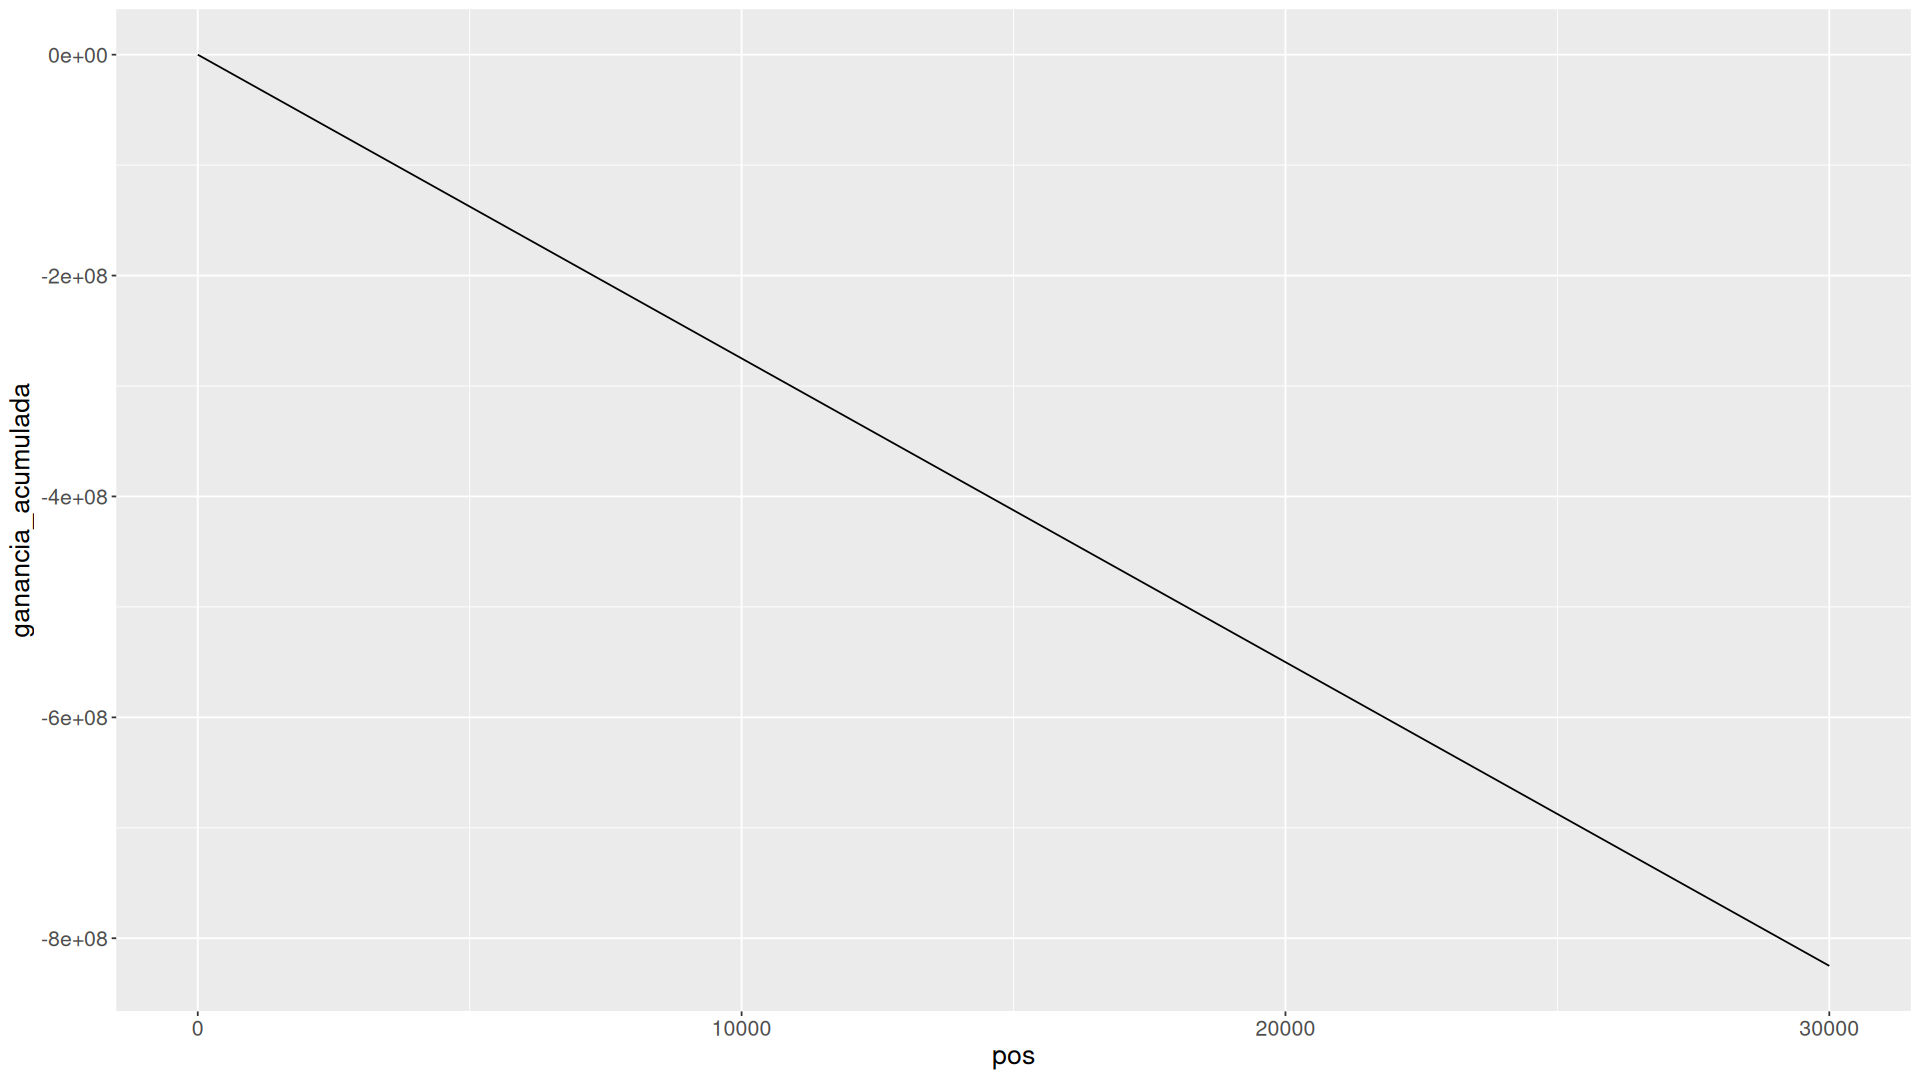

In [111]:
#%%R
# observamos la curva de ganancia

# defino hasta donde muestra el grafico
amostrar <- 30000

gra <- ggplot(
           data= tb_prediccion[pos <= amostrar],
           aes( x= pos, y= ganancia_acumulada)
             ) + geom_line()

gra <- gra + theme(text = element_text(size = 16))

options(repr.plot.width=16, repr.plot.height=9)
print( gra )

In [112]:
tb_prediccion |> head()

# Muestra los 6 clientes con mayor probabilidad de baja según el modelo, es decir el principio de la lista ordenada sobre la que se define el corte. El head() solo imprime las primeras 6 filas.

numero_de_cliente,foto_mes,clase_ternaria,prob,gan,ganancia_acumulada,pos
<dbl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<int>
24241017,202108,,0.9974818,-27500,-27500,1
23214907,202108,,0.9966565,-27500,-55000,2
44098430,202108,,0.9965646,-27500,-82500,3
70417732,202108,,0.9964043,-27500,-110000,4
57157011,202108,,0.9955843,-27500,-137500,5
53836627,202108,,0.9925680,-27500,-165000,6


Qué se ve en esas 6 filas:
- Las probabilidades van de 0,999 a 0,988, o sea que **el modelo está casi seguro de que esos clientes se van. Sin embargo, ninguno es BAJA+2: hay 2 BAJA+1 y 4 CONTINUA.** Como solo BAJA+2 paga, los 6 valen -27.500 y la ganancia acumulada baja de a 27.500 por fila hasta -165.000 en la posición 6 (6 × 27.500).
- Un arranque negativo no significa que el modelo esté mal. **La ganancia total de un corte recién se ve después de miles de clientes: en tu tabla de cortes la curva termina en +411 M en 11.000 envíos. Seis filas son una muestra chica para juzgar nada.**

Lo que sí llama la atención
- Que las probabilidades sean tan cercanas a 1 es raro para un problema donde las bajas son muy pocas. El modelo final entrena sin undersampling, así que esperaría probabilidades más bajas, aunque las de los mejores sigan siendo relativamente altas. Junto con que los primeros 6 no acierten ninguna BAJA+2, es señal de un modelo muy confiado.
- Puede deberse a que tiene mucha capacidad (364 hojas, 3253 árboles, min_data_in_leaf = 0) y se ajusta demasiado al entrenamiento. No es un problema del código, es algo que se ve al mirar el resultado.

Para chequearlo, mirá la distribución de prob en junio:

In [113]:
#summary(tb_prediccion$prob)
#tb_prediccion[, .(n = .N, bajas2 = sum(clase_ternaria == "BAJA+2")),
#              by = .(tramo = cut(prob, c(0, .1, .5, .9, 1)))]

In [114]:
#tb_prediccion[, .(n = .N,
#                  bajas = sum(clase_ternaria %in% c("BAJA+1", "BAJA+2")),
#                  prob_media = mean(prob)),
#              by = .(tramo = cut(prob, c(0, .1, .5, .9, 1)))][
#  , tasa_real := bajas / n][]

In [115]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 03:12:36 2026"

## Revisamos ganancia bajo distintos cortes

In [116]:
PARAM

$experimento
[1] "HT4955-01"

$semilla_primigenia
[1] 600013

$train
[1] 202103 202104

$train_final
[1] 202103 202104 202105 202106

$validate
[1] 202106

$future
[1] 202108

$semilla_kaggle
[1] 600013

$cortes
 [1]  4000  4200  4400  4600  4800  5000  5200  5400  5600  5800  6000  6200
[13]  6400  6600  6800  7000  7200  7400  7600  7800  8000  8200  8400  8600
[25]  8800  9000  9200  9400  9600  9800 10000 10200 10400 10600 10800 11000
[37] 11200 11400 11600 11800 12000 12200 12400 12600 12800 13000 13200 13400
[49] 13600 13800 14000 14200 14400 14600 14800 15000 15200 15400 15600 15800
[61] 16000 16200 16400 16600 16800 17000 17200 17400 17600 17800 18000 18200
[73] 18400 18600 18800 19000

$training_pct
[1] 70

$trainingstrategy
$trainingstrategy$undersampling
[1] 1


$hyperparametertuning
$hyperparametertuning$xval_folds
[1] 5

$hyperparametertuning$iteraciones
[1] 50


$lgbm
$lgbm$param_fijos
$lgbm$param_fijos$boosting
[1] "gbdt"

$lgbm$param_fijos$objective
[1] "binary"

$lgbm$param_fijos$metric
[1] "auc"

$lgbm$param_fijos$feature_pre_filter
[1] FALSE

$lgbm$param_fijos$first_metric_only
[1] FALSE

$lgbm$param_fijos$boost_from_average
[1] TRUE

$lgbm$param_fijos$force_row_wise
[1] TRUE

$lgbm$param_fijos$deterministic
[1] TRUE

$lgbm$param_fijos$verbosity
[1] -100

$lgbm$param_fijos$seed
[1] 600013

$lgbm$param_fijos$max_depth
[1] -1

$lgbm$param_fijos$min_gain_to_split
[1] 0

$lgbm$param_fijos$lambda_l1
[1] 0

$lgbm$param_fijos$lambda_l2
[1] 0

$lgbm$param_fijos$max_bin
[1] 31

$lgbm$param_fijos$bagging_fraction
[1] 1

$lgbm$param_fijos$pos_bagging_fraction
[1] 1

$lgbm$param_fijos$neg_bagging_fraction
[1] 1

$lgbm$param_fijos$is_unbalance
[1] FALSE

$lgbm$param_fijos$scale_pos_weight
[1] 1

$lgbm$param_fijos$drop_rate
[1] 0.1

$lgbm$param_fijos$max_drop
[1] 50

$lgbm$param_fijos$skip_drop
[1] 0.5

$lgbm$param_fijos$extra_trees
[1] FALSE

$lgbm$param_fijos$early_stopping
[1] 0

$lgbm$param_fijos$min_data_in_leaf
[1] 0

$lgbm$param_fijos$feature_fraction
[1] 0.5

$lgbm$param_fijos$feature_fraction_bynode
[1] 1

$lgbm$param_fijos$learning_rate
[1] 0.005

$lgbm$param_fijos$num_iterations
[1] 20000

$lgbm$param_fijos$num_leaves
[1] 1024

$lgbm$param_fijos$min_sum_hessian_in_leaf
[1] 1e-06


$lgbm$param_iniciales30
$lgbm$param_iniciales30$boosting
[1] "gbdt"

$lgbm$param_iniciales30$objective
[1] "binary"

$lgbm$param_iniciales30$metric
[1] "average_precision"

$lgbm$param_iniciales30$feature_pre_filter
[1] FALSE

$lgbm$param_iniciales30$first_metric_only
[1] FALSE

$lgbm$param_iniciales30$boost_from_average
[1] TRUE

$lgbm$param_iniciales30$force_row_wise
[1] TRUE

$lgbm$param_iniciales30$deterministic
[1] TRUE

$lgbm$param_iniciales30$verbosity
[1] -100

$lgbm$param_iniciales30$seed
[1] 600013

$lgbm$param_iniciales30$max_depth
[1] -1

$lgbm$param_iniciales30$min_gain_to_split
[1] 0

$lgbm$param_iniciales30$lambda_l1
[1] 0

$lgbm$param_iniciales30$lambda_l2
[1] 0

$lgbm$param_iniciales30$max_bin
[1] 31

$lgbm$param_iniciales30$bagging_fraction
[1] 1

$lgbm$param_iniciales30$pos_bagging_fraction
[1] 1

$lgbm$param_iniciales30$neg_bagging_fraction
[1] 1

$lgbm$param_iniciales30$is_unbalance
[1] FALSE

$lgbm$param_iniciales30$scale_pos_weight
[1] 1

$lgbm$param_iniciales30$drop_rate
[1] 0.1

$lgbm$param_iniciales30$max_drop
[1] 50

$lgbm$param_iniciales30$skip_drop
[1] 0.5

$lgbm$param_iniciales30$extra_trees
[1] FALSE

$lgbm$param_iniciales30$early_stopping
[1] 0

$lgbm$param_iniciales30$min_data_in_leaf
[1] 0

$lgbm$param_iniciales30$feature_fraction
[1] 0.5

$lgbm$param_iniciales30$learning_rate
[1] 0.005

$lgbm$param_iniciales30$num_iterations
[1] 2180

$lgbm$param_iniciales30$num_leaves
[1] 30

$lgbm$param_iniciales30$min_sum_hessian_in_leaf
[1] 0.1141634



$out
$out$lgbm
$out$lgbm$mejores_hiperparametros
$out$lgbm$mejores_hiperparametros$num_iterations
[1] 3606

$out$lgbm$mejores_hiperparametros$num_leaves
[1] 1443

$out$lgbm$mejores_hiperparametros$min_sum_hessian_in_leaf
[1] 0.08745181

$out$lgbm$mejores_hiperpara

In [117]:
#%%R
# inicilizo el dataset  drealidad
drealidad <- realidad_inicializar( dfuture, PARAM)

#`Función realidad_inicializar`:
#Prepara la "tabla de la realidad" para calcular la ganancia real de cada corte, simulando el leaderboard de Kaggle.
#- Se queda con tres columnas de dfuture: numero_de_cliente, foto_mes y clase_ternaria. Esta última es la verdad, lo que realmente pasó con cada cliente.
#- Le agrega una columna fold con particionar(..., division = c(3, 7), agrupa = "clase_ternaria"). Es el mismo reparto estratificado que vimos antes: 30 % de los clientes al fold 1 (el "Public") y 70 % al fold 2 (el "Private"), manteniendo esa proporción dentro de cada clase.
#- Devuelve el resultado, que después usa realidad_evaluar para calcular ganancia total, Public y Private.

In [118]:
head(drealidad)

numero_de_cliente,foto_mes,clase_ternaria,fold
<dbl>,<int>,<chr>,<dbl>
12159854,202108,,1
12159858,202108,,1
12160484,202108,,2
12160591,202108,,1
12160747,202108,,2
12160769,202108,,2


In [119]:
head(tb_prediccion)

numero_de_cliente,foto_mes,clase_ternaria,prob,gan,ganancia_acumulada,pos
<dbl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<int>
24241017,202108,,0.9974818,-27500,-27500,1
23214907,202108,,0.9966565,-27500,-55000,2
44098430,202108,,0.9965646,-27500,-82500,3
70417732,202108,,0.9964043,-27500,-110000,4
57157011,202108,,0.9955843,-27500,-137500,5
53836627,202108,,0.9925680,-27500,-165000,6


In [120]:
PARAM$cortes

[1]  4000  4200  4400  4600  4800  5000  5200  5400  5600  5800  6000  6200
[13]  6400  6600  6800  7000  7200  7400  7600  7800  8000  8200  8400  8600
[25]  8800  9000  9200  9400  9600  9800 10000 10200 10400 10600 10800 11000
[37] 11200 11400 11600 11800 12000 12200 12400 12600 12800 13000 13200 13400
[49] 13600 13800 14000 14200 14400 14600 14800 15000 15200 15400 15600 15800
[61] 16000 16200 16400 16600 16800 17000 17200 17400 17600 17800 18000 18200
[73] 18400 18600 18800 19000

In [121]:
#%%R
# genero archivos con los  "envios" mejores
# suba TODOS los archivos a Kaggle

# ordeno por probabilidad descendente
setorder(tb_prediccion, -prob)

for (envios in PARAM$cortes) {
  tb_prediccion[, Predicted := 0L] # seteo inicial a 0
  tb_prediccion[1:envios, Predicted := 1L] # marco los primeros

  res <- realidad_evaluar( drealidad, tb_prediccion)

  options(scipen = 999)
  cat( "Envios=", envios, "\t",
    " TOTAL=", res$total,
    "  Public=", res$public,
    " Private=", res$private,
    "\n",
    sep= ""
  )

}

Envios=4000	 TOTAL=-110000000  Public=-110458333 Private=-109803571
Envios=4200	 TOTAL=-115500000  Public=-116325000 Private=-115146429
Envios=4400	 TOTAL=-121000000  Public=-122008333 Private=-120567857
Envios=4600	 TOTAL=-126500000  Public=-127875000 Private=-125910714
Envios=4800	 TOTAL=-132000000  Public=-132641667 Private=-131725000
Envios=5000	 TOTAL=-137500000  Public=-138233333 Private=-137185714
Envios=5200	 TOTAL=-143000000  Public=-144283333 Private=-142450000
Envios=5400	 TOTAL=-148500000  Public=-150516667 Private=-147635714
Envios=5600	 TOTAL=-154000000  Public=-156475000 Private=-152939286
Envios=5800	 TOTAL=-159500000  Public=-160600000 Private=-159028571
Envios=6000	 TOTAL=-165000000  Public=-165733333 Private=-164685714
Envios=6200	 TOTAL=-170500000  Public=-171233333 Private=-170185714
Envios=6400	 TOTAL=-176000000  Public=-175541667 Private=-176196429
Envios=6600	 TOTAL=-181500000  Public=-180766667 Private=-181814286
Envios=6800	 TOTAL=-187000000  Public=-185166667

In [122]:
# el original era 
# write_yaml( PARAM, file="PARAM.yml")

# 1. Guardar el ParamSet en un archivo RDS
saveRDS(PARAM$hypeparametertuning$hs, file = "hs_paramset.rds")

# 2. Reemplazar el objeto por la ruta en tu lista PARAM
PARAM_yaml <- PARAM
PARAM_yaml$hypeparametertuning$hs <- "hs_paramset.rds"

# 3. Escribir el YAML sin errores
yaml::write_yaml(PARAM_yaml, file = "PARAM.yml")

In [123]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 03:12:39 2026"

## Importancia de las variables

In [124]:
# ahora imprimo la importancia de variables

tb_importancia <- as.data.table(lgb.importance(modelo_final))
archivo_importancia <- "impo.txt"

setwd(file.path(DIR_EXP, experimento))

# Al haber usado setwd(), al poner solo "impo.txt" se guarda adentro de exp...
fwrite(tb_importancia,
  file = "impo.txt",
  sep = "\t"
)

In [125]:
tb_importancia
# Gain (Ganancia): Es la métrica principal de importancia. Indica cuánto mejora la precisión del modelo cada vez que se utiliza esta variable para dividir los datos en un árbol. A mayor valor, más relevante es la variable para predecir.
# Cover (Cobertura): Representa la proporción relativa de observaciones (o datos) que pasan por los nodos donde se utiliza esta variable.
# Frequency (Frecuencia): Mide el porcentaje o proporción de veces que la variable fue elegida para hacer una división a lo largo de todos los árboles del modelo.

Feature,Gain,Cover,Frequency
<chr>,<dbl>,<dbl>,<dbl>
ctrx_quarter_normalizado,0.022630913,0.008154207,0.0090259061
cpayroll_tot,0.019501787,0.006638938,0.0010086378
mpasivos_margen,0.016829942,0.006139307,0.0068705483
mcaja_ahorro,0.014258222,0.008059218,0.0060155005
ctrx_quarter,0.013119498,0.004953604,0.0063834366
mcuentas_saldo,0.011307495,0.011654467,0.0077795544
mpayroll_sobre_edad,0.010991756,0.008024930,0.0099990674
cpayroll_trx,0.008643602,0.002805982,0.0003896044
numero_de_cliente,0.008149119,0.010284597,0.0161031530


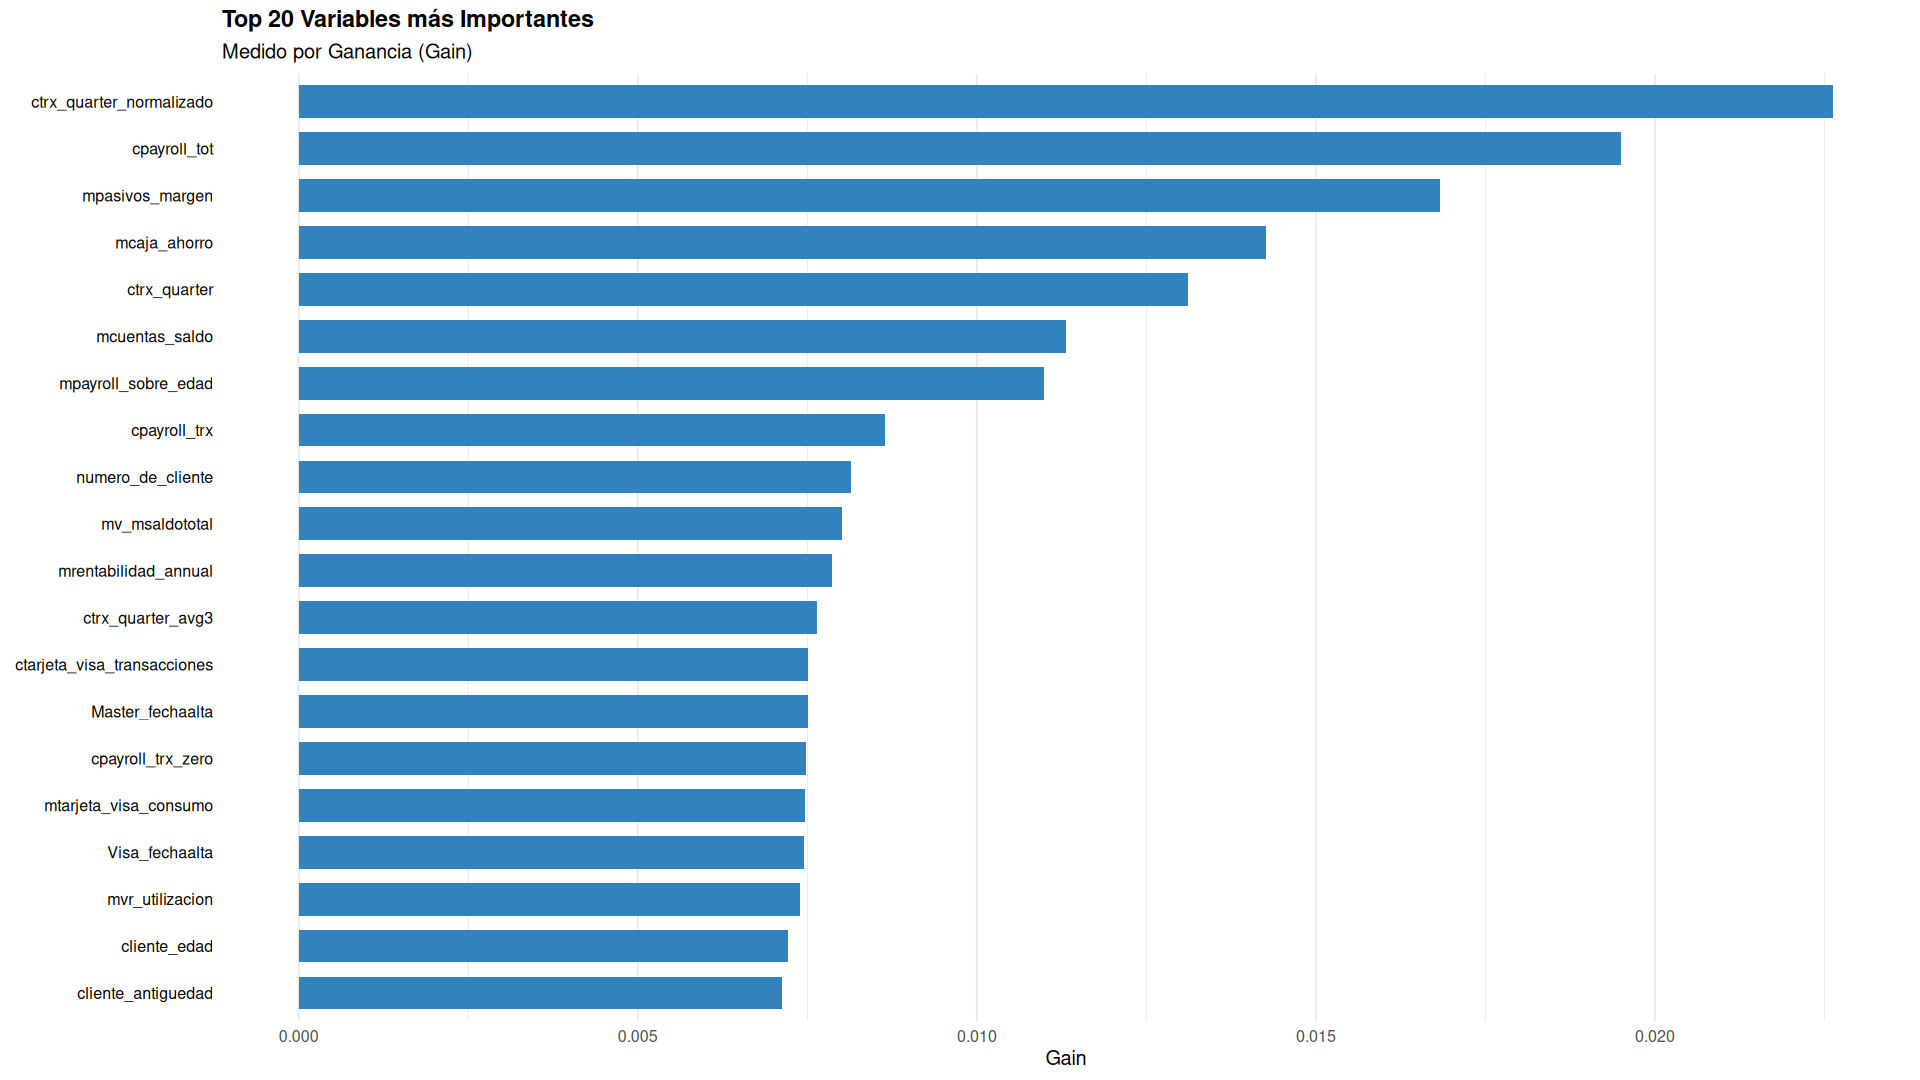

In [126]:
# Tomamos las 20 variables más importantes por Gain
tb_importancia %>%
  head(20) %>%
  ggplot(aes(x = reorder(Feature, Gain), y = Gain)) +
  geom_col(fill = "#3182bd", width = 0.7) +
  coord_flip() +
  labs(
    title = "Top 20 Variables más Importantes",
    subtitle = "Medido por Ganancia (Gain)",
    x = NULL,
    y = "Gain"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    plot.title = element_text(face = "bold", size = 14),
    axis.text.y = element_text(color = "black")
  )

Finalmente usted deberá cargar el resultado de su corrida en la Google Sheet Colaborativa,  hoja **TareaHogar04**
<br> Siéntase libre de agregar las columnas que hagan falta a la planilla

## Variabilidad por semilla
Realizo el **entrenamiento del modelo final** con **varias semillas (mismos hiperparámetros)** y evalúo la ganancia en cada corte, más el promedio de las semillas.

La BO sigue usando una sola semilla (semilla_primigenia = 600013), como antes. Las 5 semillas solo se aplican al entrenamiento final, que es lo que queríamos.

In [128]:
# ---- Variabilidad por semilla: mismos hiperparametros, cambia solo la semilla ----
#PARAM$semillas <- c(600013, 620003, 640007, 660007, 680003)  
PARAM$semillas <- c(
  600013, 620003, 640007  # las 5 tuyas, sin cambios
)

X_future <- data.matrix(dfuture[, campos_buenos, with= FALSE]) #selecciona un conjunto de columnas específicas de una tabla y las convierte en una matriz numérica
predicciones <- matrix(NA_real_, nrow= nrow(dfuture), ncol= length(PARAM$semillas)) #crea una matriz vacía llamada predicciones, que se utiliza para almacenar los resultados que generarán múltiples modelos (entrenados con distintas semillas aleatorias) para cada registro de dfuture.

tb_resultados <- data.table(semilla= character(), envios= numeric(),total= numeric(), public= numeric(), private= numeric())

# evalua todos los cortes para un vector de probabilidades y devuelve una tabla
evaluar_cortes <- function(prob, etiqueta) {
  tb_pred <- dfuture[, list(numero_de_cliente, foto_mes)]
  tb_pred[, prob := prob]
  setorder(tb_pred, -prob)

  filas <- list()
  for (envios in PARAM$cortes) {
    tb_pred[, Predicted := 0L]
    tb_pred[1:envios, Predicted := 1L]
    res <- realidad_evaluar(drealidad, tb_pred)
    filas[[length(filas) + 1]] <- list(etiqueta, envios, res$total, res$public, res$private)
  }
  rbindlist(filas)
}

for (i in seq_along(PARAM$semillas)) {
  semilla <- PARAM$semillas[i]
  gc()

  param_semilla <- copy(param_final)
  param_semilla$seed <- semilla          # lo unico que cambia entre corridas

  modelo <- lgb.train(data= dtrain_final, param= param_semilla)
  lgb.save(modelo, paste0("modelo_", semilla, ".txt"))
  predicciones[, i] <- predict(modelo, X_future)

  tb_resultados <- rbind(tb_resultados,
                         evaluar_cortes(predicciones[, i], as.character(semilla)),
                         use.names= FALSE)

  fwrite(tb_resultados, "resultados_semillas.txt", sep= "\t")   # grabo en cada vuelta
}

# el promedio de las semillas, evaluado igual
tb_resultados <- rbind(tb_resultados,
                       evaluar_cortes(rowMeans(predicciones), "promedio"),
                       use.names= FALSE)
fwrite(tb_resultados, "resultados_semillas.txt", sep= "\t")


In [129]:
# resumen: cuanto varia la ganancia segun la semilla en cada corte
resumen <- tb_resultados[semilla != "promedio",
  list(media= mean(total), desvio= sd(total), minimo= min(total), maximo= max(total)),
  by= envios]

prom <- tb_resultados[semilla == "promedio", list(envios, total_promedio= total)]
resumen <- merge(resumen, prom, by= "envios")
resumen


envios,media,desvio,minimo,maximo,total_promedio
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4000,-110000000,0,-110000000,-110000000,-110000000
4200,-115500000,0,-115500000,-115500000,-115500000
4400,-121000000,0,-121000000,-121000000,-121000000
4600,-126500000,0,-126500000,-126500000,-126500000
4800,-132000000,0,-132000000,-132000000,-132000000
5000,-137500000,0,-137500000,-137500000,-137500000
5200,-143000000,0,-143000000,-143000000,-143000000
5400,-148500000,0,-148500000,-148500000,-148500000
5600,-154000000,0,-154000000,-154000000,-154000000


In [130]:
head(drealidad)

numero_de_cliente,foto_mes,clase_ternaria,fold
<dbl>,<int>,<chr>,<dbl>
12159854,202108,,1
12159858,202108,,1
12160484,202108,,2
12160591,202108,,1
12160747,202108,,2
12160769,202108,,2


In [131]:
head(tb_prediccion)

numero_de_cliente,foto_mes,clase_ternaria,prob,gan,ganancia_acumulada,pos,Predicted
<dbl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>
24241017,202108,,0.9974818,-27500,-27500,1,1
23214907,202108,,0.9966565,-27500,-55000,2,1
44098430,202108,,0.9965646,-27500,-82500,3,1
70417732,202108,,0.9964043,-27500,-110000,4,1
57157011,202108,,0.9955843,-27500,-137500,5,1
53836627,202108,,0.9925680,-27500,-165000,6,1


In [132]:
PARAM$cortes

[1]  4000  4200  4400  4600  4800  5000  5200  5400  5600  5800  6000  6200
[13]  6400  6600  6800  7000  7200  7400  7600  7800  8000  8200  8400  8600
[25]  8800  9000  9200  9400  9600  9800 10000 10200 10400 10600 10800 11000
[37] 11200 11400 11600 11800 12000 12200 12400 12600 12800 13000 13200 13400
[49] 13600 13800 14000 14200 14400 14600 14800 15000 15200 15400 15600 15800
[61] 16000 16200 16400 16600 16800 17000 17200 17400 17600 17800 18000 18200
[73] 18400 18600 18800 19000

In [133]:
#%%R
# genero archivos con los  "envios" mejores
# suba TODOS los archivos a Kaggle

# ordeno por probabilidad descendente
setorder(tb_prediccion, -prob)

for (envios in PARAM$cortes) {
  tb_prediccion[, Predicted := 0L] # seteo inicial a 0
  tb_prediccion[1:envios, Predicted := 1L] # marco los primeros

  res <- realidad_evaluar( drealidad, tb_prediccion)

  options(scipen = 999)
  cat( "Envios=", envios, "\t",
    " TOTAL=", res$total,
    "  Public=", res$public,
    " Private=", res$private,
    "\n",
    sep= ""
  )

}

Envios=4000	 TOTAL=-110000000  Public=-110458333 Private=-109803571
Envios=4200	 TOTAL=-115500000  Public=-116325000 Private=-115146429
Envios=4400	 TOTAL=-121000000  Public=-122008333 Private=-120567857
Envios=4600	 TOTAL=-126500000  Public=-127875000 Private=-125910714
Envios=4800	 TOTAL=-132000000  Public=-132641667 Private=-131725000
Envios=5000	 TOTAL=-137500000  Public=-138233333 Private=-137185714
Envios=5200	 TOTAL=-143000000  Public=-144283333 Private=-142450000
Envios=5400	 TOTAL=-148500000  Public=-150516667 Private=-147635714
Envios=5600	 TOTAL=-154000000  Public=-156475000 Private=-152939286
Envios=5800	 TOTAL=-159500000  Public=-160600000 Private=-159028571
Envios=6000	 TOTAL=-165000000  Public=-165733333 Private=-164685714
Envios=6200	 TOTAL=-170500000  Public=-171233333 Private=-170185714
Envios=6400	 TOTAL=-176000000  Public=-175541667 Private=-176196429
Envios=6600	 TOTAL=-181500000  Public=-180766667 Private=-181814286
Envios=6800	 TOTAL=-187000000  Public=-185166667

In [134]:
# el original era 
# write_yaml( PARAM, file="PARAM.yml")

# 1. Guardar el ParamSet en un archivo RDS
saveRDS(PARAM$hypeparametertuning$hs, file = "hs_paramset.rds")

# 2. Reemplazar el objeto por la ruta en tu lista PARAM
PARAM_yaml <- PARAM
PARAM_yaml$hypeparametertuning$hs <- "hs_paramset.rds"

# 3. Escribir el YAML sin errores
yaml::write_yaml(PARAM_yaml, file = "PARAM_semillas.yml")

In [135]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 05:21:35 2026"

4000 	 -110000000 
4200 	 -115500000 
4400 	 -121000000 
4600 	 -126500000 
4800 	 -132000000 
5000 	 -137500000 
5200 	 -143000000 
5400 	 -148500000 
5600 	 -154000000 
5800 	 -159500000 
6000 	 -165000000 
6200 	 -170500000 
6400 	 -176000000 
6600 	 -181500000 
6800 	 -187000000 
7000 	 -192500000 
7200 	 -198000000 
7400 	 -203500000 
7600 	 -209000000 
7800 	 -214500000 
8000 	 -220000000 
8200 	 -225500000 
8400 	 -231000000 
8600 	 -236500000 
8800 	 -242000000 
9000 	 -247500000 
9200 	 -253000000 
9400 	 -258500000 
9600 	 -264000000 
9800 	 -269500000 
10000 	 -275000000 
10200 	 -280500000 
10400 	 -286000000 
10600 	 -291500000 
10800 	 -297000000 
11000 	 -302500000 
11200 	 -308000000 
11400 	 -313500000 
11600 	 -319000000 
11800 	 -324500000 
12000 	 -330000000 
12200 	 -335500000 
12400 	 -341000000 
12600 	 -346500000 
12800 	 -352000000 
13000 	 -357500000 
13200 	 -363000000 
13400 	 -368500000 
13600 	 -374000000 
13800 	 -379500000 
14000 	 -385000000 
14200 	 -3

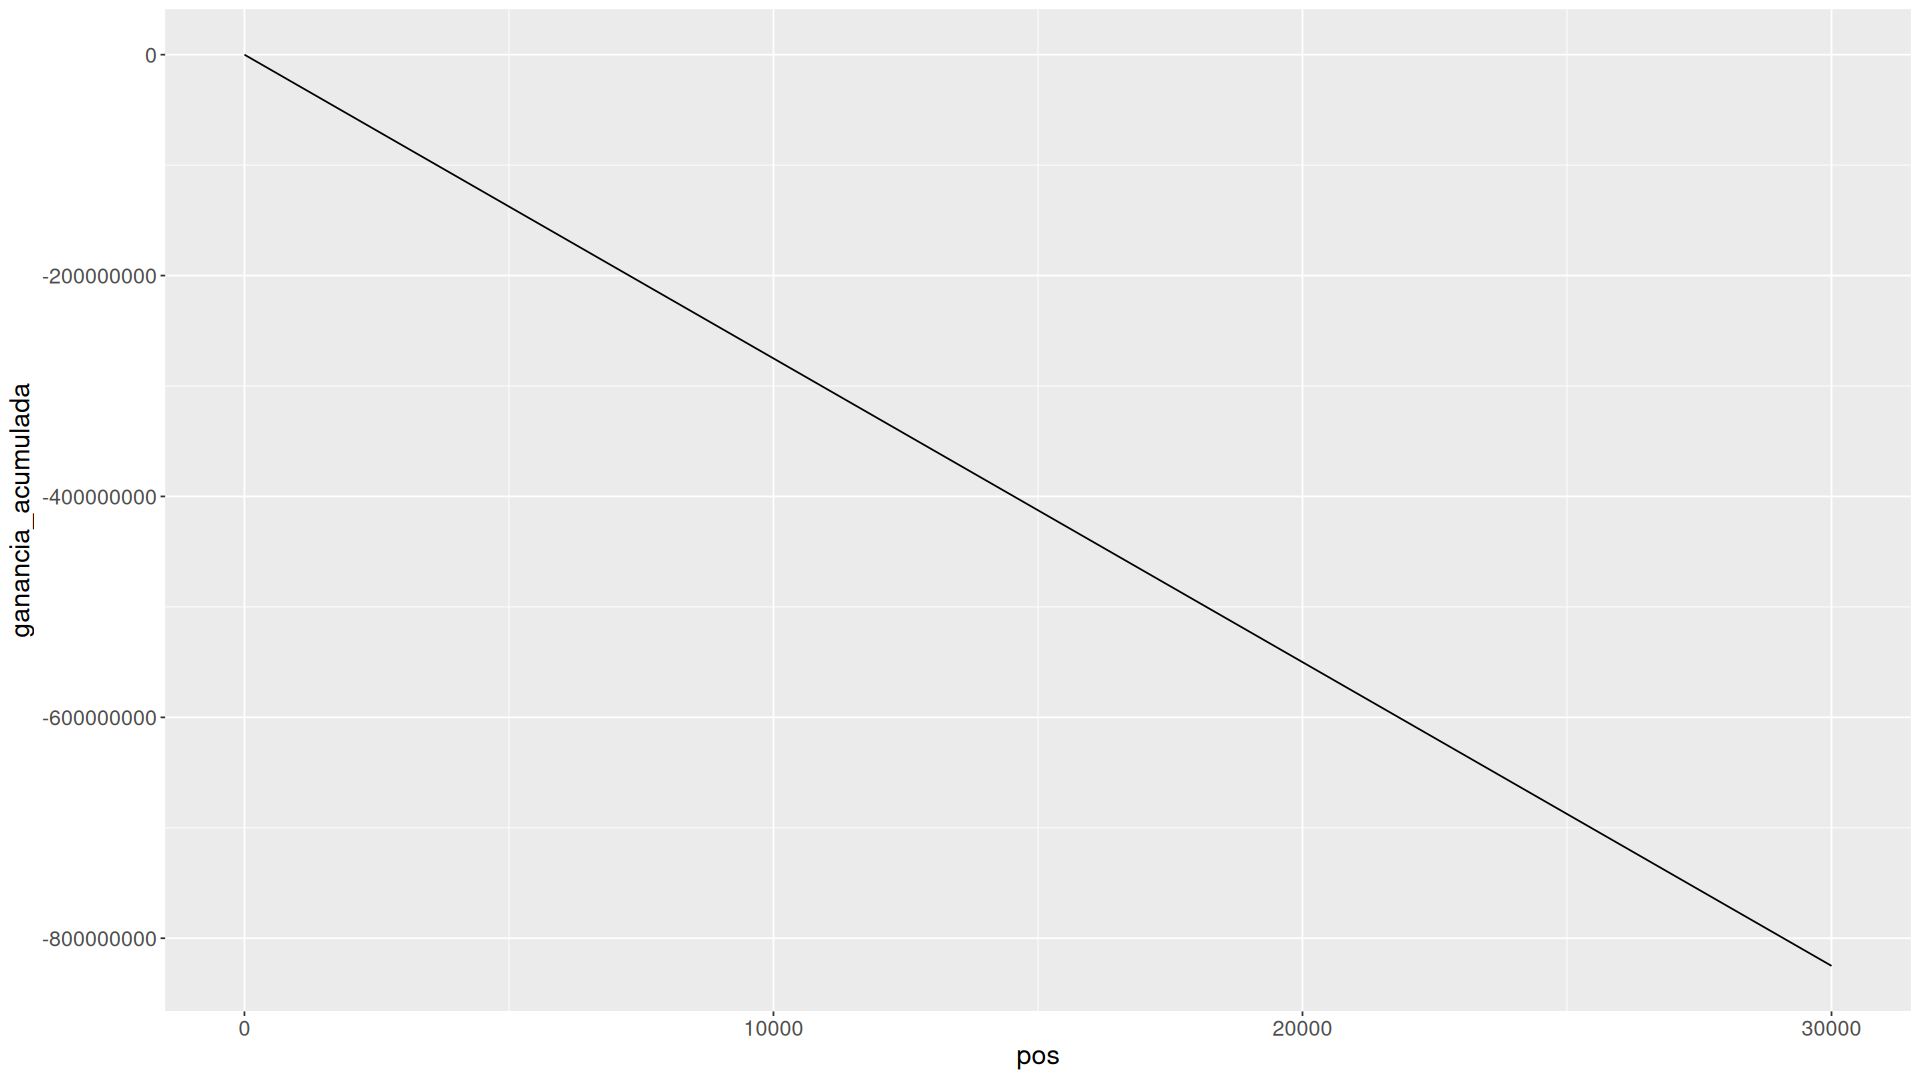

In [136]:
# ---- Uso el promedio de las semillas como predicción ----
prediccion <- rowMeans(predicciones)

# ---- (celda 174) tabla de predicción ----
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]
tb_prediccion[, prob := prediccion]
tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)]

setwd(file.path(DIR_EXP, experimento))

# grabo las probabilidades del modelo promedio
fwrite(tb_prediccion[, list(numero_de_cliente, foto_mes, prob, gan)],
  file = "prediccion_promedio.txt",
  sep = "\t"
)

# ---- (celda 176) curva de ganancia acumulada ----
setorder(tb_prediccion, -prob)

tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

for (envios in PARAM$cortes) {
  ganancia <- tb_prediccion[1:envios, sum(gan)]
  cat(envios, "\t", ganancia, "\n")
}

# ---- (celda 177) gráfico de la curva de ganancia ----
amostrar <- 30000

gra <- ggplot(
  data= tb_prediccion[pos <= amostrar],
  aes(x= pos, y= ganancia_acumulada)
) + geom_line()

gra <- gra + theme(text = element_text(size = 16))

options(repr.plot.width=16, repr.plot.height=9)
print(gra)

# ---- (celda 189) ganancia en cada corte: total, Public y Private ----
setorder(tb_prediccion, -prob)

for (envios in PARAM$cortes) {
  tb_prediccion[, Predicted := 0L]
  tb_prediccion[1:envios, Predicted := 1L]

  res <- realidad_evaluar(drealidad, tb_prediccion)

  options(scipen = 999)
  cat("Envios=", envios, "\t",
    " TOTAL=", res$total,
    "  Public=", res$public,
    " Private=", res$private,
    "\n",
    sep= ""
  )
}

In [137]:
# media (y dispersión) de la ganancia entre semillas, para cada corte
resumen_completo <- tb_resultados[semilla != "promedio",
  list(
    total_media   = mean(total),
    total_desvio  = sd(total),
    public_media  = mean(public),
    private_media = mean(private)
  ),
  by= envios]

# ganancia del ensamble (promedio de probabilidades), para comparar
ensamble <- tb_resultados[semilla == "promedio",
  list(envios, total_ensamble= total)]

resumen_completo <- merge(resumen_completo, ensamble, by= "envios")
setorder(resumen_completo, envios)

options(scipen = 999)
resumen_completo

envios,total_media,total_desvio,public_media,private_media,total_ensamble
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4000,-110000000,0,-110886111,-109620238,-110000000
4200,-115500000,0,-116600000,-115028571,-115500000
4400,-121000000,0,-122191667,-120489286,-121000000
4600,-126500000,0,-127600000,-126028571,-126500000
4800,-132000000,0,-132977778,-131580952,-132000000
5000,-137500000,0,-138844444,-136923810,-137500000
5200,-143000000,0,-144038889,-142554762,-143000000
5400,-148500000,0,-149783333,-147950000,-148500000
5600,-154000000,0,-155313889,-153436905,-154000000


Las dos formas de "promediar" no son lo mismo
- total_media (azul): promedia las ganancias de 5 modelos evaluados por separado. Responde a "¿cuánto gano en promedio si uso una sola semilla?".
- total_ensamble (rojo): promedia primero las probabilidades de los 5 modelos y evalúa el ranking resultante. Responde a "¿cuánto gano si uso los 5 modelos juntos?".

In [ ]:
ggplot() +
  geom_line(data= tb_resultados[semilla != "promedio"],
            aes(x= envios, y= total, group= semilla),
            color= "grey70") +
  geom_line(data= resumen_completo,
            aes(x= envios, y= total_media),
            color= "blue", linewidth= 1.2) +
  geom_line(data= resumen_completo,
            aes(x= envios, y= total_ensamble),
            color= "red", linewidth= 1.2, linetype= "dashed") +
  theme_minimal() +
  labs(title= "Ganancia por corte según semilla",
       subtitle= "Gris: cada semilla | Azul: media de ganancias | Rojo: ganancia del promedio de probabilidades",
       x= "Envíos", y= "Ganancia total")

In [138]:
resumen_completo[which.max(total_media), list(envios, total_media)]

envios,total_media
<dbl>,<dbl>
4000,-110000000


In [139]:
resumen_completo[which.max(total_ensamble), list(envios, total_ensamble)]

envios,total_ensamble
<dbl>,<dbl>
4000,-110000000


Finalmente, entre tanta lista de instrucciones, algo conceptual:

En la materia Data Mining sufrieron descarnadamente el overfitting, un modelo que funcionaba bien en el Public Leaderboard era muy malo en el Private. Eran presa de La maldicion del ganador

Para evitar eso, ahora en sus notebooks, en la parte final de generaicion del modelo final con LightGBM, generan varios modelos, cada uno solamente cambiando el hipeparametro seed de LightGBM y con el resto de los hiperparametros identicos.

Cada uno de estos modelos genera una prediccion sobre los datos del futuro, el mes 202108

Esos multiples archivos (hasta 20) son los que entregan en un submit, y el generoso bot, a diferencia del traicionero Zulip, les devuelve la media y la varianza de esas ganancias, con lo cual reducen enormemente el overfitting.
(tecnicamente NO lo eliminan por completo)

## Archivo final de envíos
Genera un CSV **sin encabezado** con únicamente los `numero_de_cliente` a los que se envía el estímulo, usando el ensamble de las 5 semillas y el corte (cantidad de envíos) que maximiza la ganancia del ensamble. Los ids se escriben como enteros, sin notación científica.

In [ ]:
# ---- Archivo final: solo numero_de_cliente a estimular, sin encabezado ----

# corte elegido: el que maximiza la ganancia del ensamble (promedio de semillas)
#envios_final <- resumen_completo[which.max(total_ensamble), envios]
# (para fijar el corte a mano, por ejemplo: envios_final <- 11000)

# ordeno por probabilidad del ensamble (descendente) y me quedo con los primeros 'envios_final'
#tb_envio <- dfuture[, list(numero_de_cliente)]
#tb_envio[, prob := rowMeans(predicciones)]
#setorder(tb_envio, -prob)
#ids_estimulo <- tb_envio[1:envios_final, numero_de_cliente]

# ids como enteros: nada de notacion cientifica
# (format(..., scientific=FALSE) garantiza digitos completos, tambien si superan el rango de integer de 32 bits)
#ids_txt <- format(as.numeric(ids_estimulo), scientific= FALSE, trim= TRUE)
#stopifnot(!any(grepl("[eE.]", ids_txt)))   # control: ni notacion cientifica ni decimales

#archivo_envio <- file.path(DIR_EXP, experimento, paste0("envio_", envios_final, ".csv"))
#archivo_envio <- file.path(DIR_EXP, experimento, "Intento01z4945.csv")
#writeLines(ids_txt, archivo_envio)         # una columna, sin encabezado, sin comillas

#cat("Archivo:", archivo_envio, "\n")
#cat("Clientes a estimular:", length(ids_txt), "\n")
#cat("Primeras lineas del archivo:\n")
#print(readLines(archivo_envio, n= 5))


In [140]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:11400, list(numero_de_cliente)],
       file = "Intentoj4955_01.csv", col.names = FALSE)

In [141]:
chk <- fread("Intentoj4955_01.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_01.csv", n = 2)   # solo números, sin nombres

[1] 11400

[1] 1

[1] 0

[1] "24241017" "44098430"

In [142]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:11600, list(numero_de_cliente)],
       file = "Intentoj4955_02.csv", col.names = FALSE)

In [143]:
chk <- fread("Intentoj4955_02.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_02.csv", n = 2)   # solo números, sin nombres

[1] 11600

[1] 1

[1] 0

[1] "24241017" "44098430"

In [144]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:11800, list(numero_de_cliente)],
       file = "Intentoj4955_03.csv", col.names = FALSE)

In [145]:
chk <- fread("Intentoj4955_03.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_03.csv", n = 2)   # solo números, sin nombres

[1] 11800

[1] 1

[1] 0

[1] "24241017" "44098430"

In [146]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:12000, list(numero_de_cliente)],
       file = "Intentoj4955_04.csv", col.names = FALSE)

In [147]:
chk <- fread("Intentoj4955_04.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_04.csv", n = 2)   # solo números, sin nombres

[1] 12000

[1] 1

[1] 0

[1] "24241017" "44098430"

In [149]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:11200, list(numero_de_cliente)],
       file = "Intentoj4955_05.csv", col.names = FALSE)

In [150]:
chk <- fread("Intentoj4955_05.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_05.csv", n = 2)   # solo números, sin nombres

[1] 11200

[1] 1

[1] 0

[1] "24241017" "44098430"

In [151]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:11000, list(numero_de_cliente)],
       file = "Intentoj4955_06.csv", col.names = FALSE)

In [152]:
chk <- fread("Intentoj4955_06.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_06.csv", n = 2)   # solo números, sin nombres

[1] 11000

[1] 1

[1] 0

[1] "24241017" "44098430"

In [159]:
setorder(tb_prediccion, -prob)
fwrite(tb_prediccion[1:10800, list(numero_de_cliente)],
       file = "Intentoj4955_07.csv", col.names = FALSE)

In [160]:
chk <- fread("Intentoj4955_07.csv", header = FALSE)
nrow(chk)                    # tiene que ser 12000
ncol(chk)                    # tiene que ser 1
anyDuplicated(chk$V1)        # tiene que ser 0
readLines("Intentoj4955_07.csv", n = 2)   # solo números, sin nombres

[1] 10800

[1] 1

[1] 0

[1] "24241017" "44098430"

In [153]:
# =====================================================================
# BACKTEST: entreno con 202103 + 202104, predigo 202106, mido ganancia
# =====================================================================
PARAM$train_bt   <- c(202103, 202104)
PARAM$test_bt    <- 202106
PARAM$semillas_bt <- c(600013, 620003, 640007, 660007, 680003)
PARAM$limpiar_dudosos_bt <- FALSE          # TRUE = aplica el cross-fitting de dudosos

dataset_bt <- dataset[foto_mes %in% PARAM$train_bt]
dtest_bt   <- dataset[foto_mes %in% PARAM$test_bt]

# --- (opcional) misma limpieza de registros dudosos que usás en el final ---
if (PARAM$limpiar_dudosos_bt) {
  particionar(dataset_bt, division= c(50, 50), agrupa= "clase_ternaria",
              campo= "fold30", seed= PARAM$semilla_primigenia)
  dataset_bt[, prob30 := NA_real_]
  for (f in 1:2) {
    dtr30 <- lgb.Dataset(
      data= data.matrix(dataset_bt[fold30 != f, campos_buenos, with= FALSE]),
      label= dataset_bt[fold30 != f, clase01], free_raw_data= TRUE)
    m30 <- lgb.train(data= dtr30, param= PARAM$lgbm$param_iniciales30)
    dataset_bt[fold30 == f, prob30 := predict(
      m30, data.matrix(dataset_bt[fold30 == f, campos_buenos, with= FALSE]))]
    rm(dtr30, m30); gc(verbose= FALSE)
  }
  dataset_bt <- dataset_bt[clase01 == 1L | prob30 < 0.5]
}
dataset_bt[, .N, list(foto_mes, clase_ternaria)][order(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181


In [154]:
# --- dataset de LightGBM (mismos pesos que el modelo final) ---
dtrain_bt <- lgb.Dataset(
  data= data.matrix(dataset_bt[, campos_buenos, with= FALSE]),
  label= dataset_bt[, clase01],
  weight= dataset_bt[, ifelse(clase_ternaria == "BAJA+1", 0.25, 1.0)]
)

In [155]:
# --- realidad de junio (junio SI tiene clase_ternaria, por eso se puede medir) ---
drealidad_bt <- realidad_inicializar(dtest_bt, PARAM)
X_test_bt    <- data.matrix(dtest_bt[, campos_buenos, with= FALSE])

evaluar_cortes_bt <- function(prob, etiqueta) {
  tb_pred <- dtest_bt[, list(numero_de_cliente, foto_mes)]
  tb_pred[, prob := prob]
  setorder(tb_pred, -prob)
  filas <- list()
  for (envios in PARAM$cortes) {
    tb_pred[, Predicted := 0L]
    tb_pred[1:envios, Predicted := 1L]
    res <- realidad_evaluar(drealidad_bt, tb_pred)
    filas[[length(filas) + 1]] <- list(etiqueta, envios, res$total, res$public, res$private)
  }
  rbindlist(filas)
}

In [156]:
# --- entreno por semilla (mismos hiperparametros que el final) ---
pred_bt <- matrix(NA_real_, nrow= nrow(dtest_bt), ncol= length(PARAM$semillas_bt))
tb_bt   <- data.table(semilla= character(), envios= numeric(),
                      total= numeric(), public= numeric(), private= numeric())

for (i in seq_along(PARAM$semillas_bt)) {
  p <- copy(param_final)
  p$seed <- PARAM$semillas_bt[i]
  m <- lgb.train(data= dtrain_bt, param= p)
  pred_bt[, i] <- predict(m, X_test_bt)
  tb_bt <- rbind(tb_bt, evaluar_cortes_bt(pred_bt[, i], as.character(PARAM$semillas_bt[i])),
                 use.names= FALSE)
  rm(m); gc(verbose= FALSE)
}

In [157]:
# --- ensamble (promedio de probabilidades) ---
tb_bt <- rbind(tb_bt, evaluar_cortes_bt(rowMeans(pred_bt), "promedio"), use.names= FALSE)
fwrite(tb_bt, "backtest_202106.txt", sep= "\t")

In [158]:
# --- resumen por corte ---
options(scipen= 999)
res_bt <- merge(
  tb_bt[semilla != "promedio",
        list(media= mean(total), desvio= sd(total),
             public= mean(public), private= mean(private)), by= envios],
  tb_bt[semilla == "promedio", list(envios, ensamble= total)], by= "envios")
setorder(res_bt, envios)
res_bt

res_bt[which.max(ensamble), list(envios, ensamble)]   # mejor corte del ensamble
res_bt[which.max(media),    list(envios, media)]      # mejor corte por media de semillas

envios,media,desvio,public,private,ensamble
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4000,280500000,3564407,285358333,278417857,280500000
4200,287320000,6479738,294066667,284428571,287100000
4400,296780000,5004698,304058333,293660714,294800000
4600,303380000,5736898,311061667,300087857,310200000
4800,310200000,3810512,317111667,307237857,312400000
5000,317680000,5064780,324775000,314639286,320100000
5200,320760000,6535518,326205000,318426429,325600000
5400,326260000,4769486,331375000,324067857,332200000
5600,331760000,5076712,336985000,329520714,337700000


envios,ensamble
<dbl>,<dbl>
12200,408100000


envios,media
<dbl>,<dbl>
13200,405460000


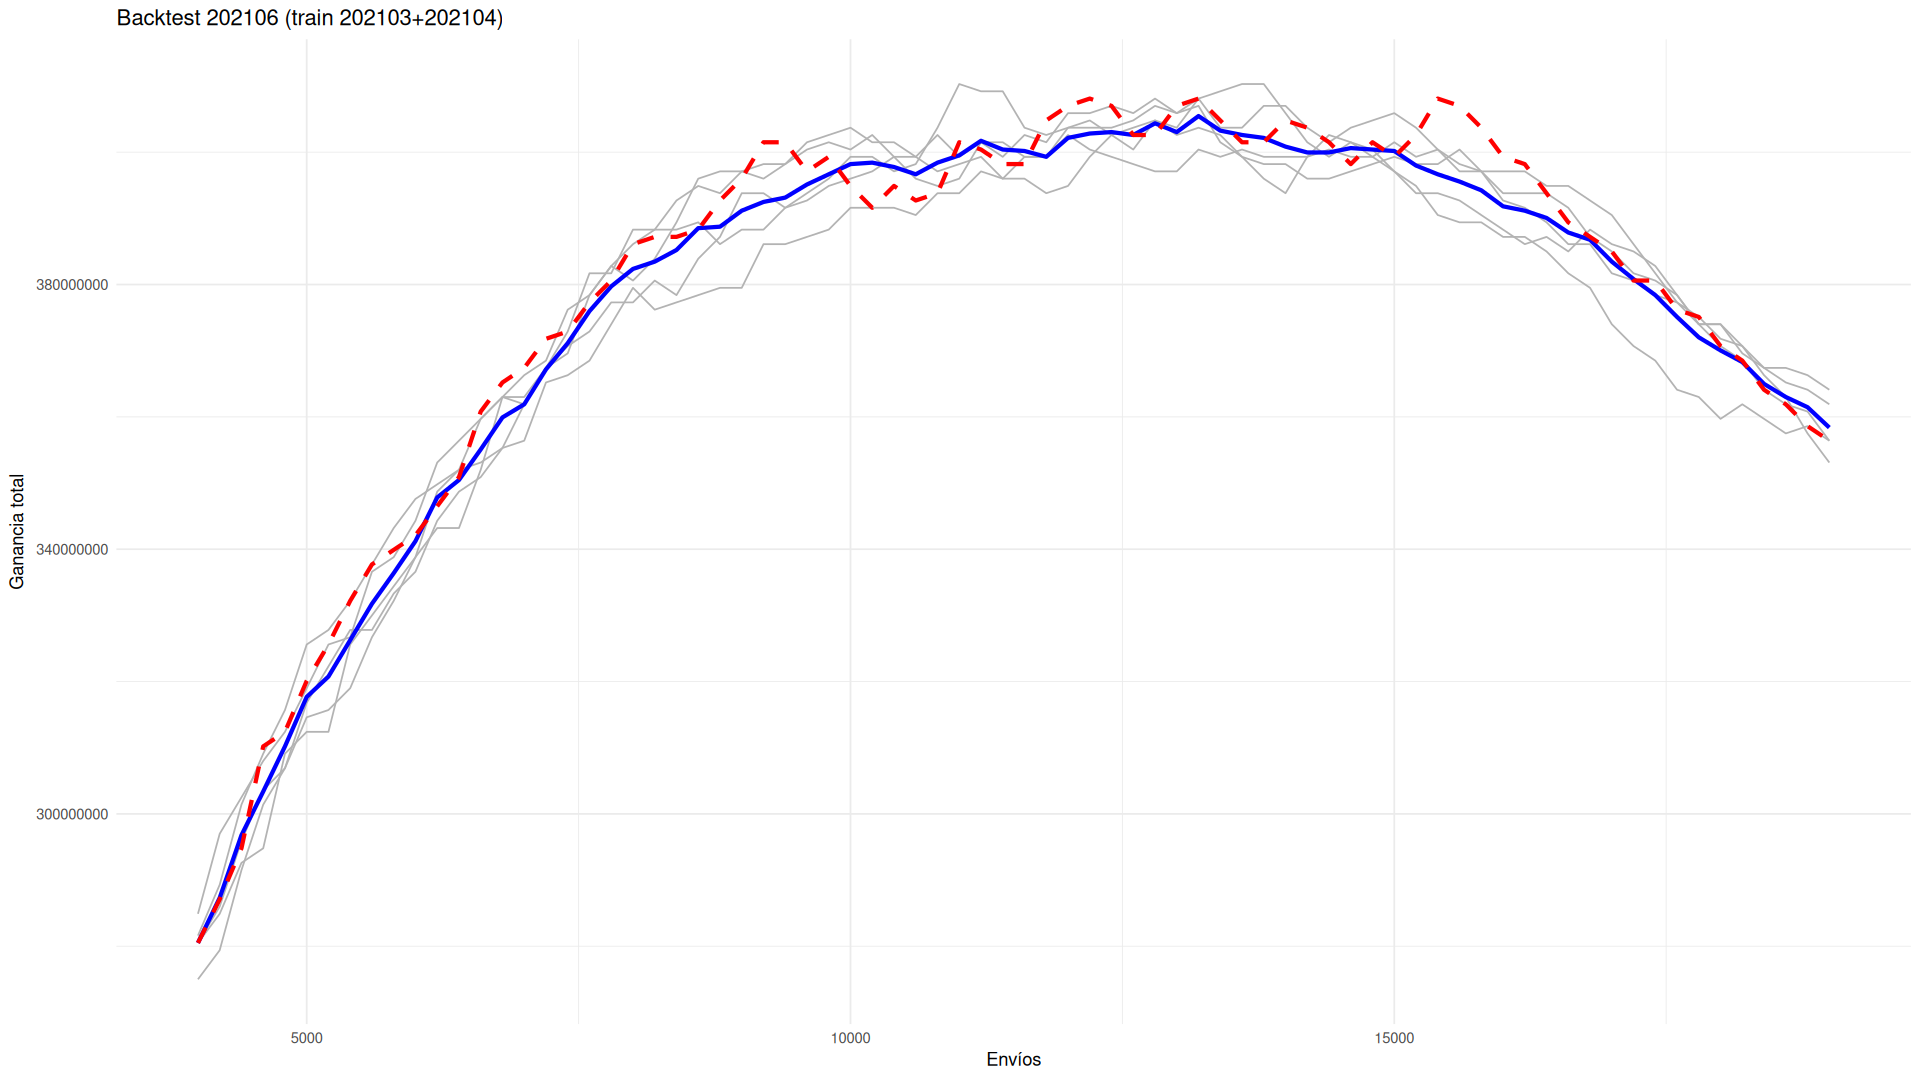

In [161]:
# curva de ganancia del backtest
ggplot() +
  geom_line(data= tb_bt[semilla != "promedio"], aes(envios, total, group= semilla), color= "grey70") +
  geom_line(data= res_bt, aes(envios, media),    color= "blue", linewidth= 1.2) +
  geom_line(data= res_bt, aes(envios, ensamble), color= "red",  linewidth= 1.2, linetype= "dashed") +
  theme_minimal() +
  labs(title= "Backtest 202106 (train 202103+202104)", x= "Envíos", y= "Ganancia total")

In [162]:
corte <- 12000
tb <- dtest_bt[, list(clase_ternaria)]
tb[, prob := rowMeans(pred_bt)]
setorder(tb, -prob)
tb[, gan := ifelse(seq_len(.N) <= corte,
                   ifelse(clase_ternaria == "BAJA+2", 1072500, -27500), 0)]

set.seed(1)
n <- nrow(tb)
sim <- replicate(5000, sum(tb$gan[sample.int(n, round(n * 0.7))]) / 0.7)
quantile(sim, c(0.01, 0.05, 0.50, 0.95))
mean(sim < 300e6)